# STOR 565 Final Project — NMF vs. PCA on Olivetti Faces
### Combined team notebook: Parts P1–P4 and a results showcase

**Question.** How does NMF represent a face as an additive combination of learned patterns, and what does it gain or lose compared with PCA?

| Part | Owner | What it does | Cells |
|---|---|---|---|
| [P1](#part-p1) | Person 1 | Data loading and the first PCA run (k = 50) | original, copied verbatim |
| [P2](#part-p2) | Person 2 | PCA analysis at k = 5, 10, 25, 50, 100 | original, copied verbatim |
| [P3](#part-p3) | Person 3 | NMF implementation at k = 40 (Chinese original) | original; one `print` line changed (marked) |
| [**P4**](#part-p4) | Person 4 | **NMF theory, optimization, interpretability, limitations, and robustness of the comparison with PCA** | revised and extended — **the focus of this notebook** |
| [Showcase](#showcase) | — | Headline numbers, talk-ready figures, suggested 12-minute flow, likely questions | new |

**How the parts are marked.** Each part starts with a banner cell. Cells copied from a teammate's notebook carry the cell tag `original-P1`, `original-P2` or `original-P3`, and their source is identical to the original notebook, with one approved exception in P3 (cell also tagged `modified-P3`): its last `print` now shows the relative output folder instead of an absolute path on the author's computer, and that line carries a comment saying so. The setup cell below is integration glue written for this combined notebook. Parts P4 and Showcase are new work.

**How to run.** Put `olivetti_preprocessed.npz` in `data/` or next to this notebook, then choose *Run All*. The full run takes about 9 minutes on one CPU thread; almost all of it is Part P4 (set `QUICK = True` in its setup cell for about half that time). Results are written to `pca_results/` (P2), `outputs/team_nmf/` (P3), `p4_results/` (P4) and `showcase/`; P1 also saves two PNG files in the working folder.

**Shared conventions.** All parts use the same 320/80 train/test split, fit only on the training images, and report per-pixel MSE on unclipped reconstructions. P1–P3 define some of the same variable names; Part P4 reloads the data and defines everything it uses, so it does not depend on the variables of earlier parts.

**Setup (integration glue — not from P1–P4).** P1 and P2 read `olivetti_preprocessed.npz` from the working folder, while P3 reads `data/olivetti_preprocessed.npz`. This cell finds the file and makes sure it is visible in both places, so that the original cells below run unchanged.

In [1]:
# Integration glue: make the shared data file visible where each original part expects it.
import hashlib
import shutil
from pathlib import Path

DATA_NAME = "olivetti_preprocessed.npz"
_search = [Path(DATA_NAME), Path("data") / DATA_NAME, Path("..") / "data" / DATA_NAME, Path("upload") / DATA_NAME]
_found = next((p for p in _search if p.is_file()), None)
if _found is None:
    raise FileNotFoundError(f"Place {DATA_NAME} in data/ or next to this notebook.")
for _target in (Path(DATA_NAME), Path("data") / DATA_NAME):       # P1/P2 use the first, P3 the second
    if not _target.is_file():
        _target.parent.mkdir(exist_ok=True)
        shutil.copyfile(_found, _target)
        print(f"Copied {_found} -> {_target}")
print(f"Data file: {_found} | sha256 {hashlib.sha256(_found.read_bytes()).hexdigest()[:16]}...")

Copied data/olivetti_preprocessed.npz -> olivetti_preprocessed.npz
Data file: data/olivetti_preprocessed.npz | sha256 85be22755fab6319...


---
<a id="part-p1"></a>
# ▌PART P1 — Person 1: data loading and first PCA run (k = 50)

> **Source:** `STOR565_Project_PCA.ipynb`. The five code cells below are copied **verbatim**; nothing was edited. (Cell 1 repeats the loading of cell 0 with a more robust file search; both are kept as the author wrote them.)
> **Role in the project:** this produced the first shared PCA number (k = 50), which Part P2 reproduces.

In [2]:
import numpy as np

data = np.load("olivetti_preprocessed.npz")

X_train = data["X_train"]
X_test = data["X_test"]
y_train = data["y_train"]
y_test = data["y_test"]

print(X_train.shape)  # (320, 4096)
print(X_test.shape)   # (80, 4096)

(320, 4096)
(80, 4096)


In [3]:
import numpy as np
from pathlib import Path

# Find the uploaded data file
candidates = [
    Path("olivetti_preprocessed.npz"),
    Path("/content/olivetti_preprocessed.npz"),
    Path("/olivetti_preprocessed.npz"),
]

data_path = next((path for path in candidates if path.is_file()), None)

if data_path is None:
    raise FileNotFoundError(
        "Upload olivetti_preprocessed.npz or specify its full path."
    )

# Load the shared training and test arrays
with np.load(data_path, allow_pickle=False) as data:
    X_train = data["X_train"]
    X_test = data["X_test"]
    y_train = data["y_train"]
    y_test = data["y_test"]

print("Training shape:", X_train.shape)  # (320, 4096)
print("Test shape:", X_test.shape)       # (80, 4096)

Training shape: (320, 4096)
Test shape: (80, 4096)


In [4]:
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA

# Fit PCA on the training data only
pca = PCA(n_components=50, svd_solver="full")
Z_train = pca.fit_transform(X_train)

# Project the test data onto the learned components
Z_test = pca.transform(X_test)

# Reconstruct the test images
X_test_reconstructed = pca.inverse_transform(Z_test)

# Calculate MSE using the raw reconstruction values without clipping
mse = np.mean((X_test - X_test_reconstructed) ** 2)
variance_retained = pca.explained_variance_ratio_.sum()

print("Original training shape:", X_train.shape)
print("Reduced training shape:", Z_train.shape)
print("Reduced test shape:", Z_test.shape)
print(f"Variance retained: {variance_retained:.2%}")
print(f"Test reconstruction MSE: {mse:.6f}")

Original training shape: (320, 4096)
Reduced training shape: (320, 50)
Reduced test shape: (80, 50)
Variance retained: 87.84%
Test reconstruction MSE: 0.003337


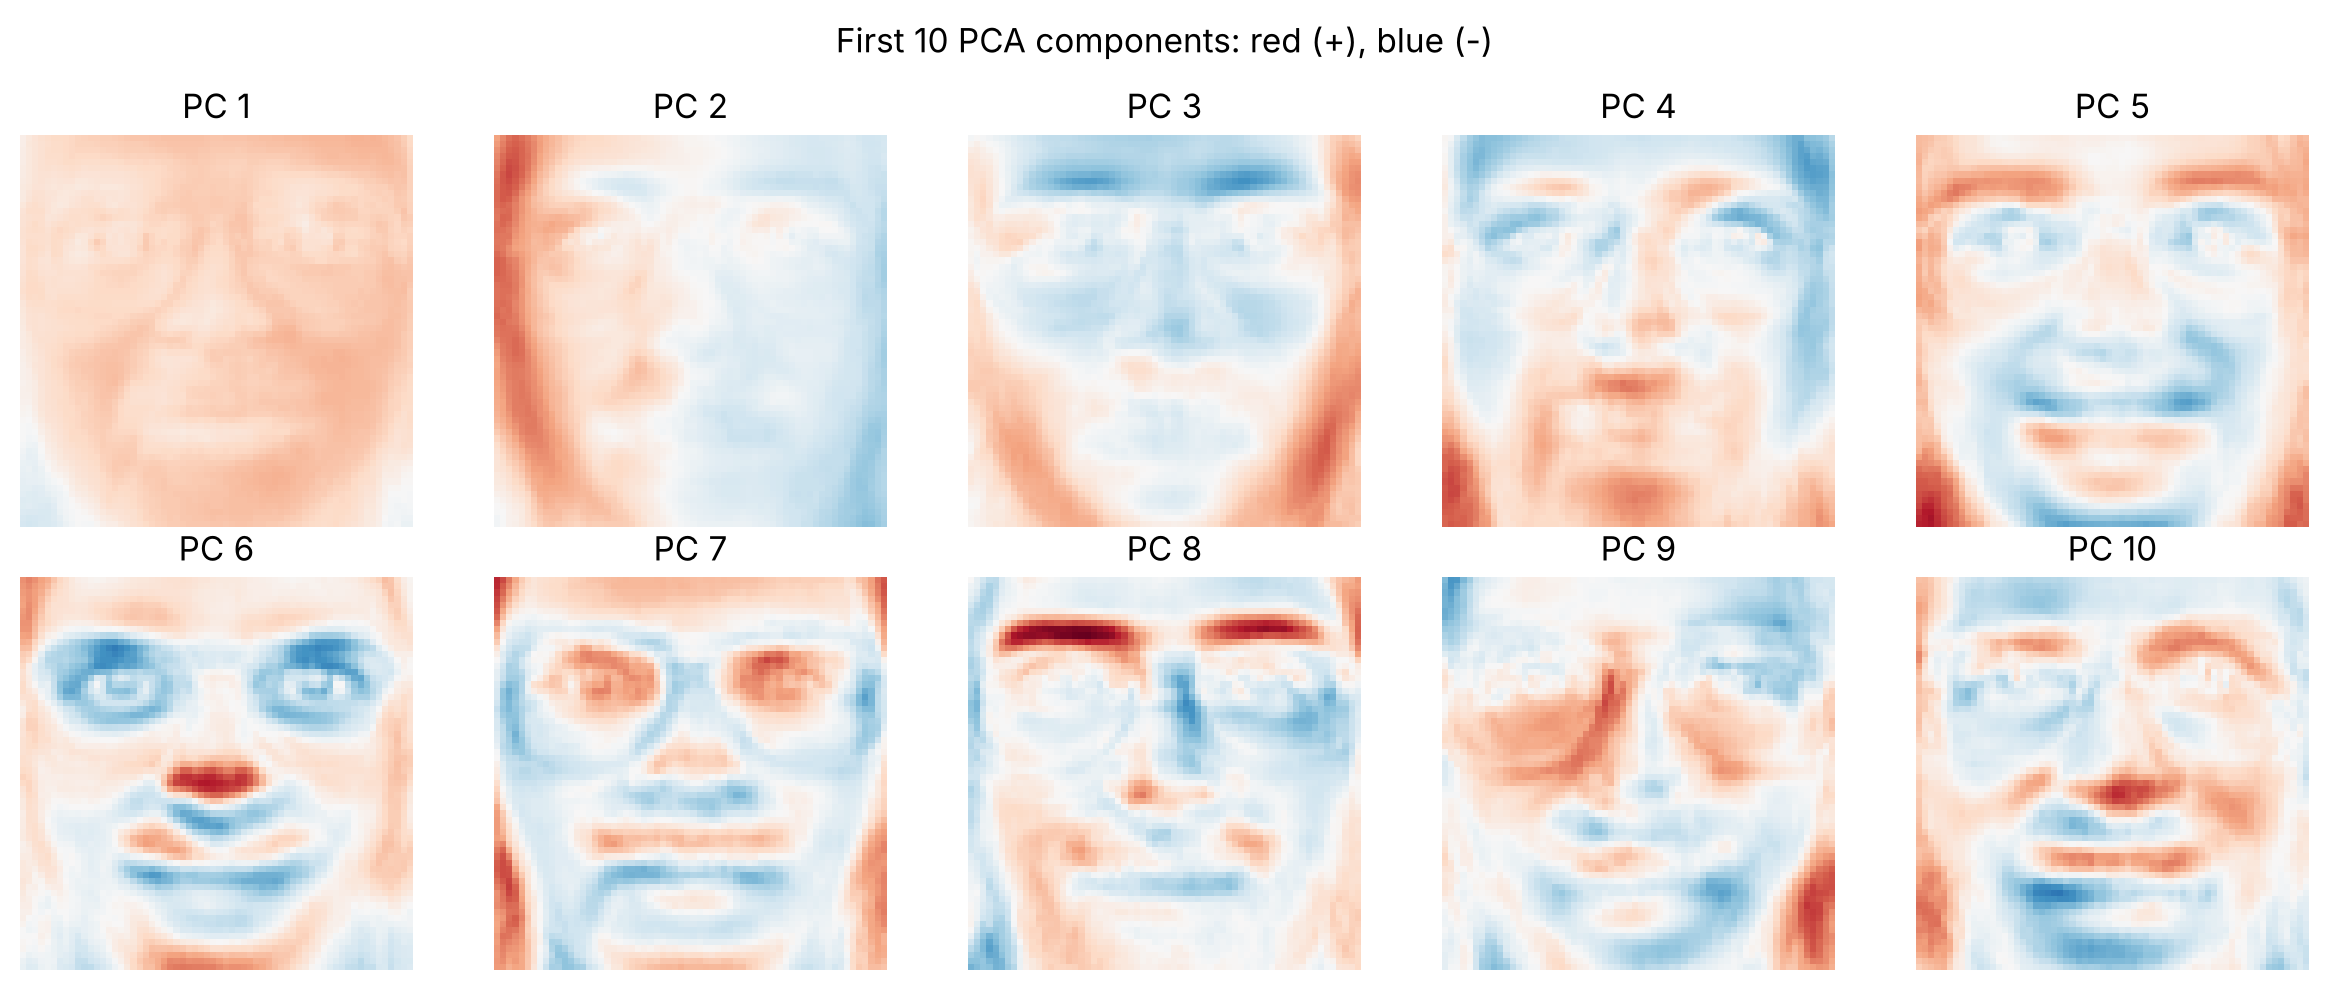

In [5]:
# Display the first 10 eigenfaces
fig, axes = plt.subplots(2, 5, figsize=(12, 5))

# Use a shared color scale centered at zero
limit = np.abs(pca.components_[:10]).max()

for i, ax in enumerate(axes.flat):
    ax.imshow(
        pca.components_[i].reshape(64, 64),
        cmap="RdBu_r",
        vmin=-limit,
        vmax=limit,
    )
    ax.set_title(f"PC {i + 1}")
    ax.axis("off")

plt.suptitle("First 10 PCA components: red (+), blue (-)")
plt.tight_layout()
plt.savefig("pca_eigenfaces.png", dpi=300, bbox_inches="tight")
plt.show()

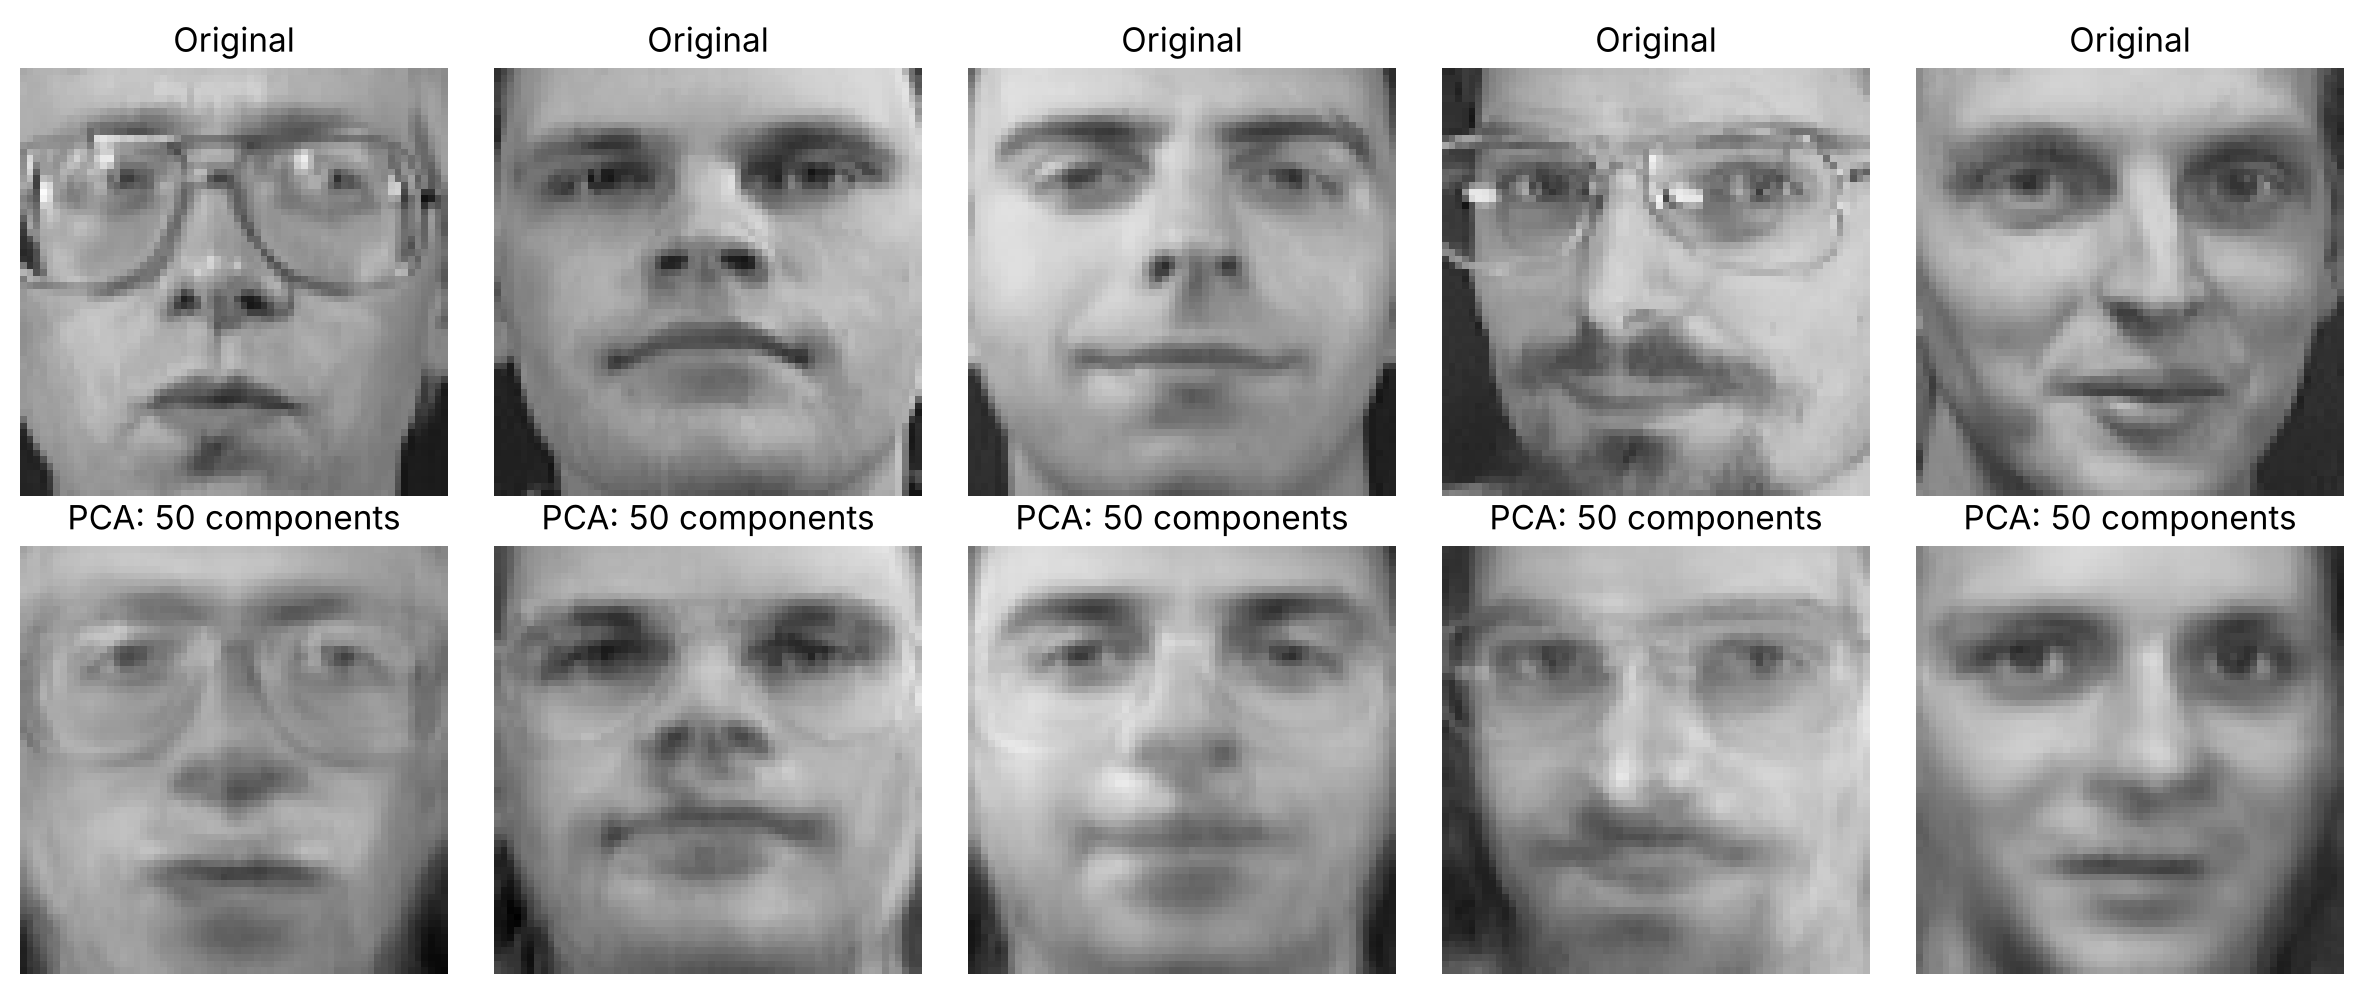

In [6]:
# Compare original and reconstructed test images
fig, axes = plt.subplots(2, 5, figsize=(12, 5))

for i in range(5):
    axes[0, i].imshow(
        X_test[i].reshape(64, 64),
        cmap="gray", vmin=0, vmax=1,
    )
    axes[1, i].imshow(
        X_test_reconstructed[i].reshape(64, 64),
        cmap="gray", vmin=0, vmax=1,
    )

    axes[0, i].set_title("Original")
    axes[1, i].set_title("PCA: 50 components")
    axes[0, i].axis("off")
    axes[1, i].axis("off")

plt.tight_layout()
plt.savefig("pca_reconstruction_k50.png", dpi=300, bbox_inches="tight")
plt.show()

---
<a id="part-p2"></a>
# ▌PART P2 — Person 2: PCA analysis of the Olivetti faces

> **Source:** `pca_analysis.ipynb`. All 13 cells (text and code) below are copied **verbatim**; nothing was edited.
> **Role in the project:** the PCA baseline at k = 5, 10, 25, 50, 100, the five fixed test images, and the unclipped per-pixel MSE definition that every other part uses. Part P4 evaluates NMF on the same component counts.

# PCA Analysis of Olivetti Faces

We used PCA to reconstruct face images with 5, 10, 25, 50, and 100 components. We compared the reconstructed images and measured their errors on the test set.

## How PCA represents a face

Each 64 × 64 image is stored as a row of 4,096 pixel values. We subtract the average training face before finding the principal directions. For the centered training matrix, the singular value decomposition is

$$X_c = U\Sigma V^\top.$$

The columns of $V$ give the principal directions, ordered by the amount of training variance they explain. Keeping the first $k$ directions gives the best rank-$k$ approximation of the centered training matrix under squared error.

For a row-vector image $x$, let $V_k$ contain these $k$ directions as columns. The coefficients and reconstruction are

$$z=(x-\mu)V_k, \qquad \hat{x}=zV_k^\top+\mu.$$

Here, $\mu$ is the training mean. The code stores directions as rows in `pca.components_`, so it transposes this array when computing the coefficients.


In [7]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from sklearn.decomposition import PCA

output = Path('pca_results')
output.mkdir(exist_ok=True)
with np.load('olivetti_preprocessed.npz', allow_pickle=False) as data:
    X_train = data['X_train'].astype(np.float64)
    X_test = data['X_test'].astype(np.float64)
    y_train, y_test = data['y_train'], data['y_test']
    train_idx, test_idx = data['train_idx'], data['test_idx']
assert X_train.shape == (320,4096) and X_test.shape == (80,4096)
assert np.isfinite(X_train).all() and np.isfinite(X_test).all()
assert len(np.intersect1d(train_idx,test_idx)) == 0
print('Training:', X_train.shape, '| Test:', X_test.shape)
print('Training images per person:', np.unique(y_train,return_counts=True)[1])
print('Test images per person:', np.unique(y_test,return_counts=True)[1])
print('NumPy', np.__version__, '| scikit-learn', sklearn.__version__)

Training: (320, 4096) | Test: (80, 4096)
Training images per person: [8 8 8 8 8 8 8 8 8 8 8 8 8 8 8 8 8 8 8 8 8 8 8 8 8 8 8 8 8 8 8 8 8 8 8 8 8
 8 8 8]
Test images per person: [2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2
 2 2 2]
NumPy 2.5.3 | scikit-learn 1.9.1


## Fitting PCA

We fitted PCA to the 320 training images and used it to transform the 80 test images. Both the mean face and the principal directions come from training data. All pixels use the same intensity scale, so we centered them without standardizing each pixel separately.

We fitted the full available basis to calculate explained variance. For the reconstruction comparison, we used the five component counts listed above.


In [8]:
pca = PCA(svd_solver='full')
pca.fit(X_train)
Z_train = pca.transform(X_train)
Z_test = pca.transform(X_test)
counts = [5,10,25,50,100]

def reconstruct(scores, k):
    return scores[:,:k] @ pca.components_[:k] + pca.mean_

assert np.allclose(pca.mean_, X_train.mean(axis=0))
assert np.allclose(pca.components_ @ pca.components_.T,
                   np.eye(len(pca.components_)), atol=1e-8)
assert np.allclose(reconstruct(Z_test, len(pca.components_)),
                   pca.inverse_transform(Z_test))
print('Fitted components:', pca.components_.shape)

Fitted components: (320, 4096)


## What the components look like

The first image below is the average training face. The other ten images are principal directions, often called eigenfaces. Red and blue show positive and negative weights on a shared scale.

PC 1 has a fairly uniform color across most of the face, with lighter weights around the eye region. This suggests a broad change in brightness rather than a change limited to one facial feature. PC 2 shows a contrast between the two sides of the face, although the red and blue regions are not divided evenly down the middle.

Among the later components, the eyebrow region is particularly noticeable in PC 8. PC 6 and PC 7 show opposite colors in some facial regions, but their spatial patterns are different. The colors indicate signed weights, so these components describe different patterns of variation rather than separate facial parts. A component's overall sign can be reversed without changing the PCA representation.


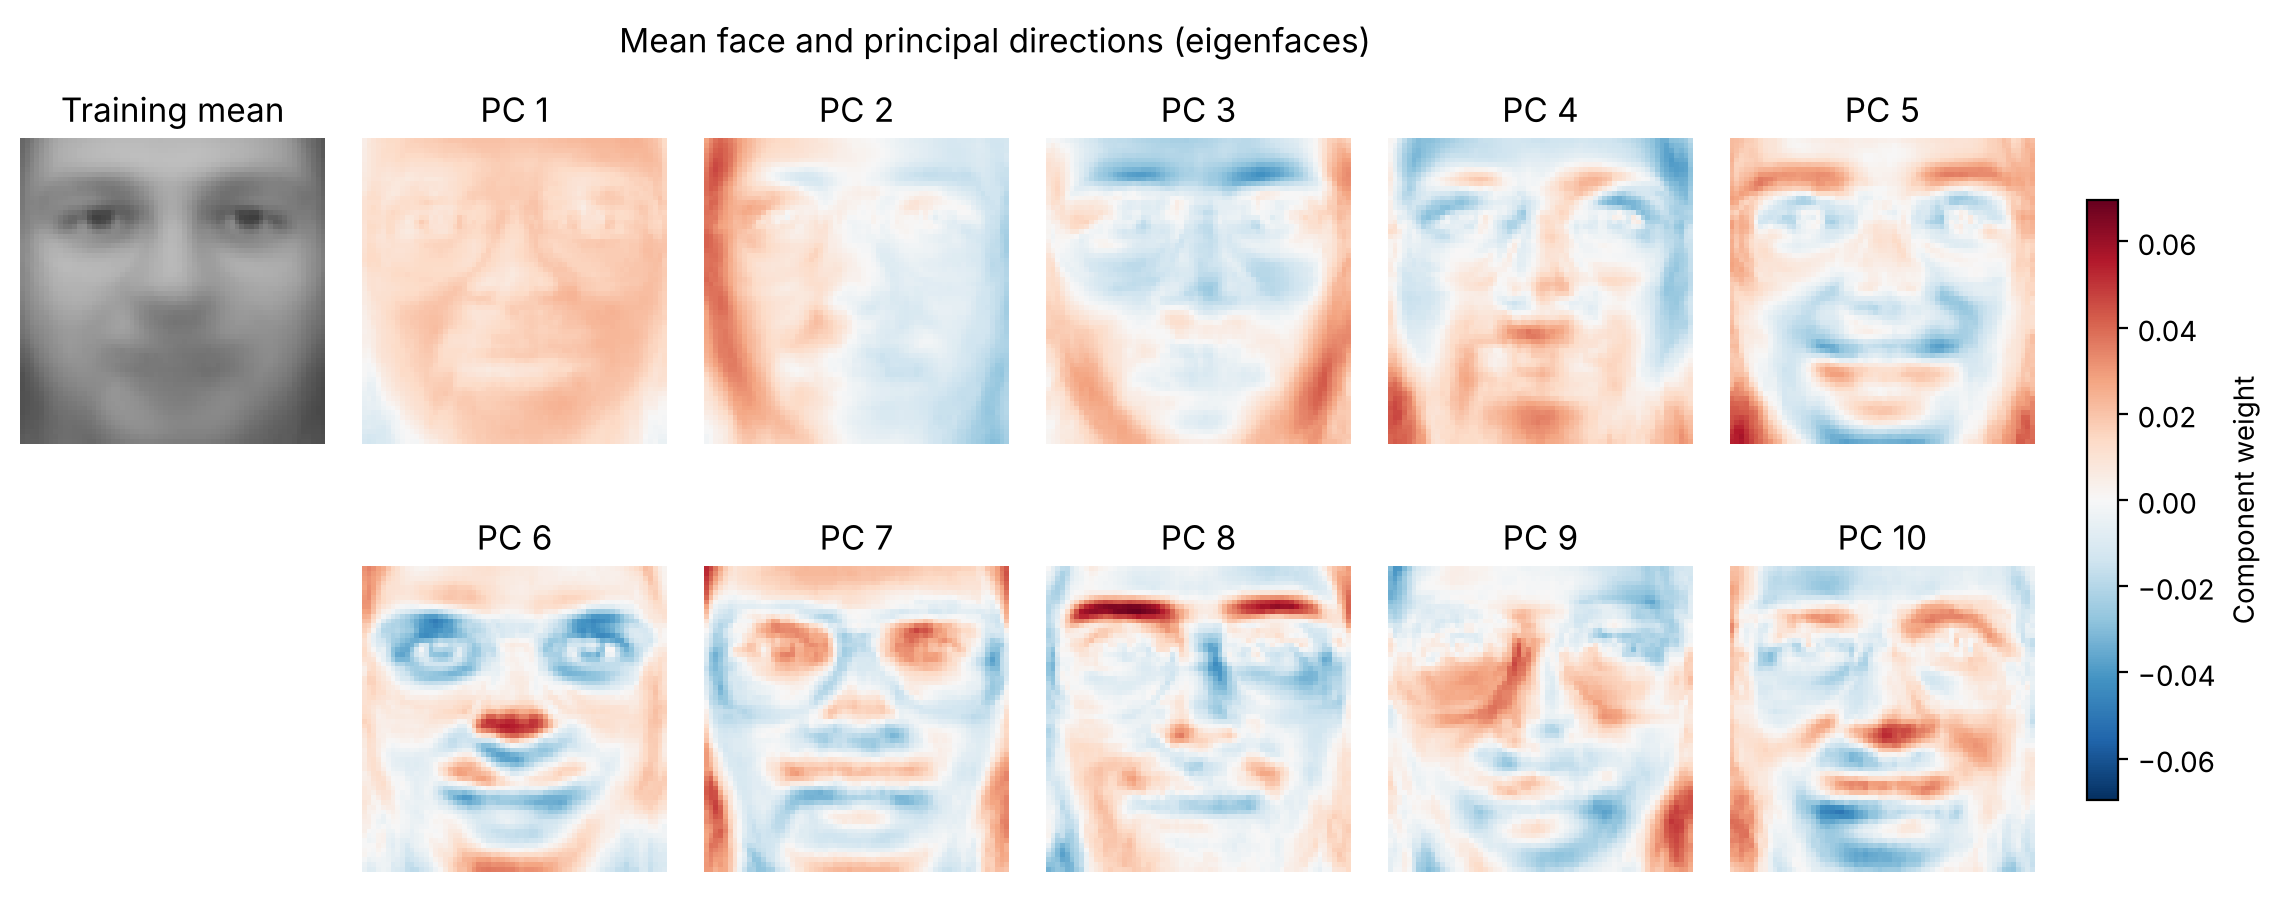

In [9]:
fig, axes = plt.subplots(2,6,figsize=(13,5))
for ax in axes.flat: ax.axis('off')
axes[0,0].imshow(pca.mean_.reshape(64,64),cmap='gray',vmin=0,vmax=1)
axes[0,0].set_title('Training mean')
limit = np.abs(pca.components_[:10]).max()
for i in range(10):
    ax = axes[i//5,i%5+1]
    im = ax.imshow(pca.components_[i].reshape(64,64),cmap='RdBu_r',vmin=-limit,vmax=limit)
    ax.set_title(f'PC {i+1}')
fig.suptitle('Mean face and principal directions (eigenfaces)')
fig.subplots_adjust(right=0.9,wspace=0.12,hspace=0.25)
cb = fig.add_axes([0.92,0.2,0.012,0.6])
fig.colorbar(im,cax=cb,label='Component weight')
fig.savefig(output/'01_pca_components.png',dpi=180,bbox_inches='tight')
plt.show()

## Reconstructing test images

Each row below shows one test image followed by its reconstructions. We used the first five test images rather than selecting examples based on their results. Every panel uses the same grayscale range.

We clipped values to [0, 1] for these displays only. The error calculations use the original, unclipped reconstructions.


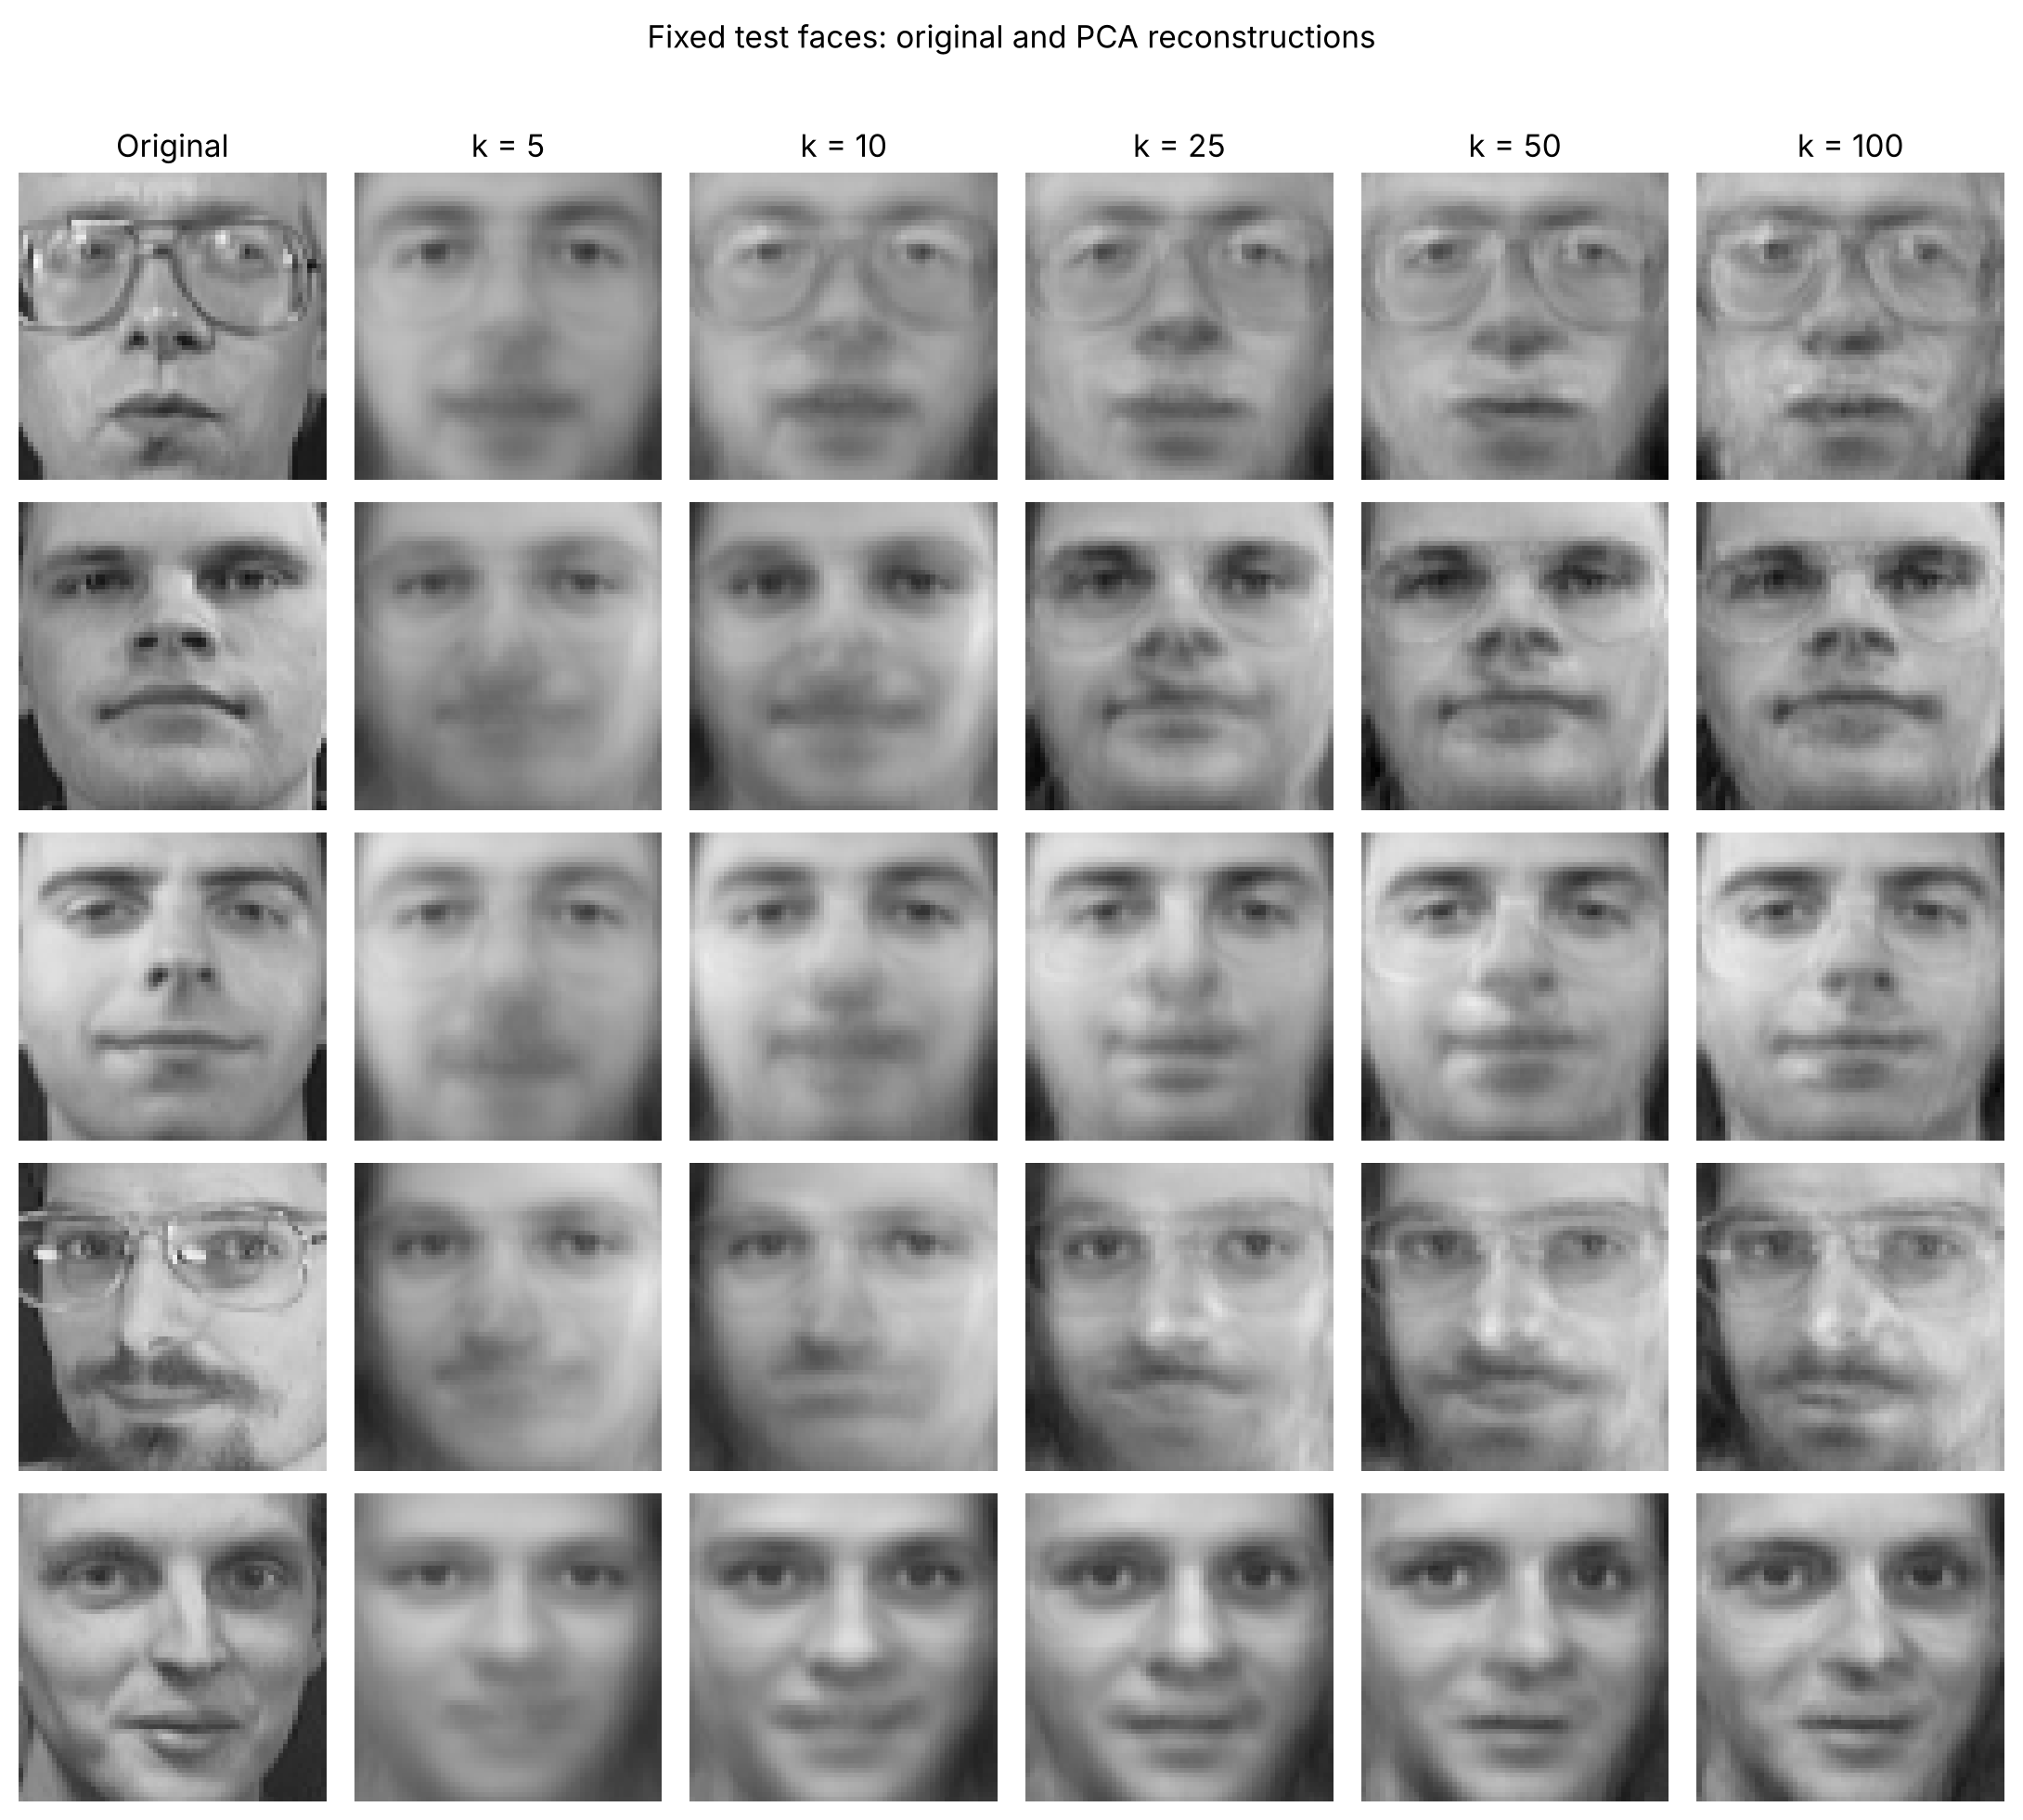

In [10]:
fig, axes = plt.subplots(5,6,figsize=(11,10))
for row in range(5):
    images = [X_test[row]] + [reconstruct(Z_test[row:row+1],k)[0] for k in counts]
    for col, image in enumerate(images):
        ax = axes[row,col]
        ax.imshow(np.clip(image,0,1).reshape(64,64),cmap='gray',vmin=0,vmax=1)
        ax.axis('off')
        if row == 0: ax.set_title('Original' if col==0 else f'k = {counts[col-1]}')
fig.suptitle('Fixed test faces: original and PCA reconstructions')
fig.tight_layout(rect=[0,0,1,0.97])
fig.savefig(output/'02_pca_reconstructions.png',dpi=180,bbox_inches='tight')
plt.show()

## Observations from the reconstructions

The reconstructions become clearer as the number of components increases, but some features require more components than others. In the first row, the glasses are recognizable at k = 10, while in the fourth row they only become reasonably recognizable at k = 50. From k = 5 to k = 25, the facial contours become clearer, and details such as the nostrils become visible.

For the examples shown, the difference between k = 50 and k = 100 is relatively small. Even at k = 100, the reconstructions remain blurrier than the originals, although the main facial features are recognizable. Based on these images, k = 50 seems to offer a reasonable balance between the number of components and visible detail: it preserves features such as glasses and the location of facial hair.

This is a visual judgment about the five displayed examples. The reconstruction MSE reported below is calculated across all 80 test images.


## Measuring reconstruction error

We calculated mean squared error over every pixel of every image:

$$\mathrm{MSE}=\frac{1}{n\times4096}\sum_{i=1}^{n}\sum_{j=1}^{4096}(x_{ij}-\hat{x}_{ij})^2.$$

The table reports training and test MSE, along with cumulative explained variance on the training set. Test images were not used to fit PCA.


In [11]:
rows=[]
for k in counts:
    rows.append({'Components':k,
                 'Train MSE':np.mean((X_train-reconstruct(Z_train,k))**2),
                 'Test MSE':np.mean((X_test-reconstruct(Z_test,k))**2),
                 'Training cumulative explained variance':pca.explained_variance_ratio_[:k].sum()})
results=pd.DataFrame(rows)
results.to_csv(output/'03_pca_results.csv',index=False)
print(results.to_string(index=False,float_format=lambda v:f'{v:.6f}'))
assert np.all(np.diff(results['Train MSE']) <= 1e-12)
assert np.all(np.diff(results['Test MSE']) <= 1e-12)
cumulative=np.cumsum(pca.explained_variance_ratio_)
for threshold in [0.9,0.95]:
    needed=int(np.searchsorted(cumulative,threshold)+1)
    print(f'{threshold:.0%} training variance requires {needed} components')
np.savez_compressed(output/'pca_model_and_results.npz',
                    mean=pca.mean_,components=pca.components_,
                    explained_variance_ratio=pca.explained_variance_ratio_,
                    Z_train=Z_train,Z_test=Z_test,component_counts=np.array(counts),
                    test_example_indices=np.arange(5))

 Components  Train MSE  Test MSE  Training cumulative explained variance
          5   0.008804  0.008860                                0.540825
         10   0.006621  0.006848                                0.654674
         25   0.003937  0.004565                                0.794667
         50   0.002331  0.003337                                0.878398
        100   0.001110  0.002503                                0.942131
90% training variance requires 62 components
95% training variance requires 111 components


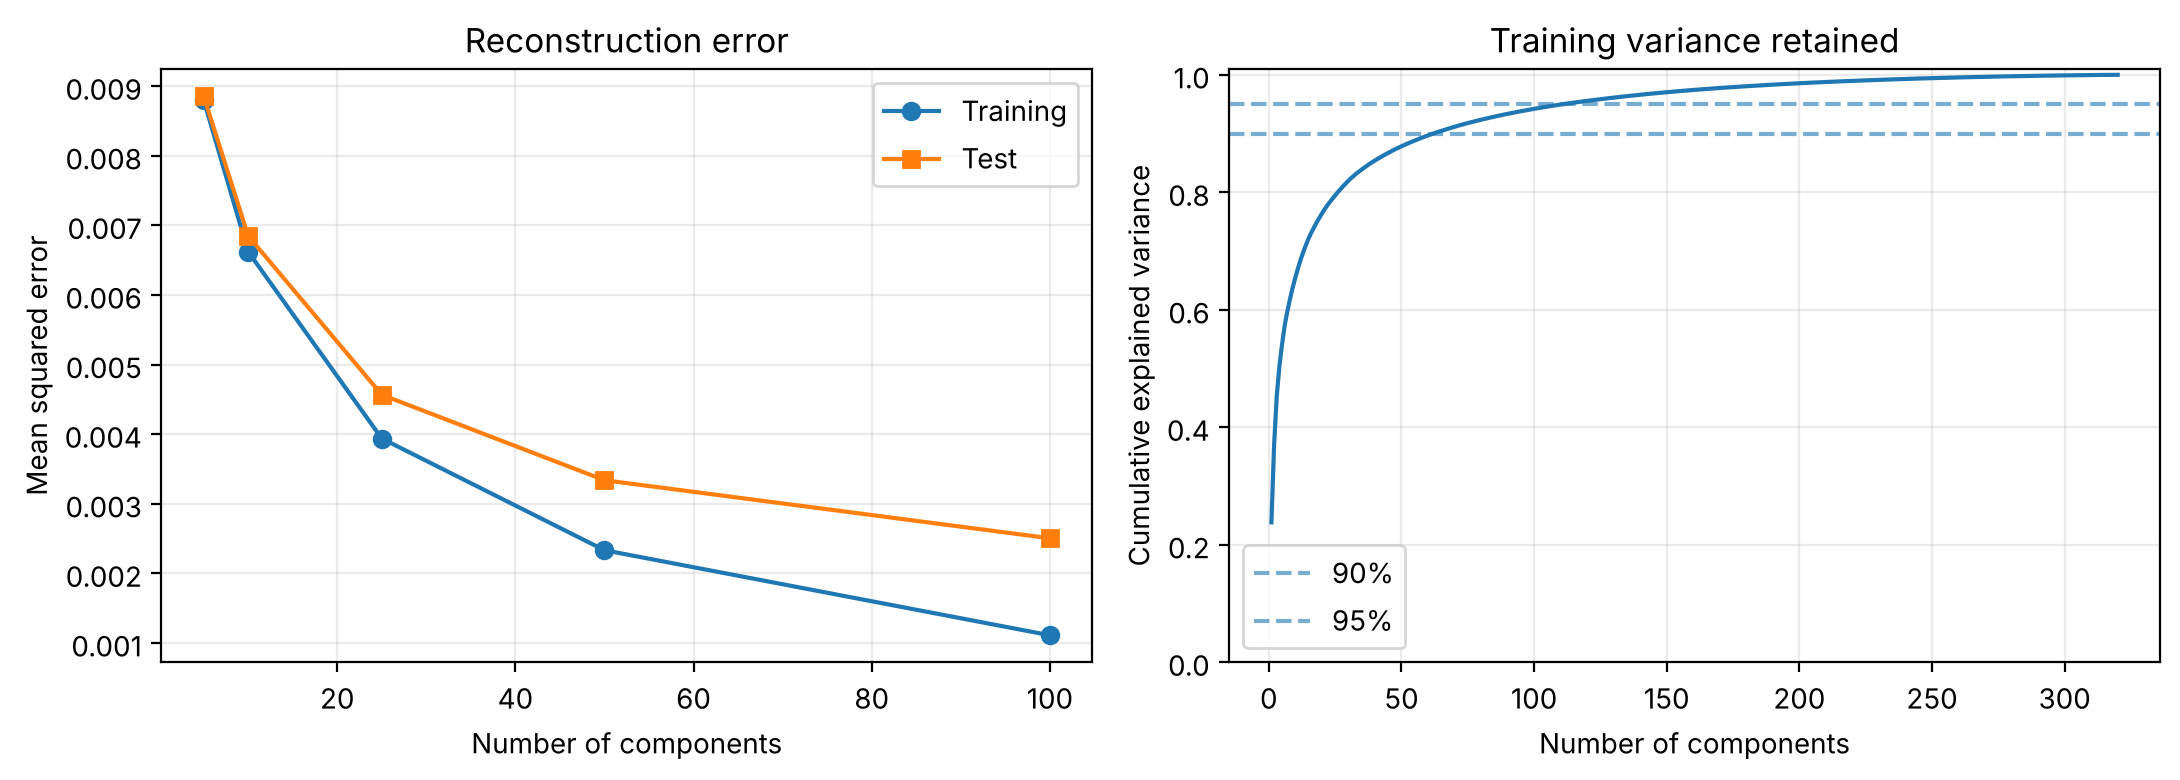

In [12]:
fig,axes=plt.subplots(1,2,figsize=(11,4))
axes[0].plot(counts,results['Train MSE'],'o-',label='Training')
axes[0].plot(counts,results['Test MSE'],'s-',label='Test')
axes[0].set(xlabel='Number of components',ylabel='Mean squared error',title='Reconstruction error')
axes[0].legend(); axes[0].grid(alpha=0.25)
axes[1].plot(np.arange(1,len(cumulative)+1),cumulative)
for threshold in [0.9,0.95]:
    axes[1].axhline(threshold,linestyle='--',alpha=0.6,label=f'{threshold:.0%}')
axes[1].set(xlabel='Number of components',ylabel='Cumulative explained variance',title='Training variance retained',ylim=(0,1.01))
axes[1].legend(); axes[1].grid(alpha=0.25)
fig.tight_layout()
fig.savefig(output/'04_pca_curves.png',dpi=180,bbox_inches='tight')
plt.show()

## Results and comparison with NMF

Test MSE decreased from 0.008860 with five components to 0.004565 with 25, a reduction of about 48.5%. Increasing from 50 to 100 components reduced it further, from 0.003337 to 0.002503. Over the tested ranges, the reduction per additional component became smaller.

The first 100 components retained 94.21% of training variance. Reaching 90% required 62 components, while 95% required 111. These percentages describe training variation; they do not measure face-recognition accuracy.

For a fixed, nested PCA basis, adding directions cannot increase squared reconstruction error. The downward error curve is therefore expected from the projection geometry. Our experiment measures reconstruction, not classification.

PCA allows both positive and negative component weights and coefficients. We will compare it with NMF using the same split, component counts, and per-pixel test MSE. The NMF results are needed before drawing conclusions about differences in reconstruction or interpretability.

Each person appears in both training and testing. The test results therefore describe new images of the same people, rather than entirely new identities.


---
<a id="part-p3"></a>
# ▌PART P3 — Person 3: NMF implementation (k = 40)

> **Source:** the team's NMF notebook (written in Chinese). All 14 cells below are copied from the original. **One line is changed**, with the owner's approval: in the last code cell (tagged `modified-P3`, change marked by a comment) the final `print` shows the relative output folder instead of the absolute path of the computer it ran on, so saved outputs no longer contain a personal path. Nothing else differs.
> **English summary of what it does:** it loads the shared split, fits scikit-learn's NMF with 40 components on the training images only (`nndsvda` initialization, coordinate descent, up to 3000 iterations, `tol=1e-4`, `random_state=42`), displays 15 learned patterns, reconstructs six fixed test images, and reports the unclipped per-pixel train and test MSE. Its settings and numbers are the reference that Part P4 reproduces and then examines.

# Person 3：直接使用组员分好的数据做 NMF

**先看照片 → 学习基础图案 → 拼回测试照片 → 看拼得有多像。**

输入是 `data/olivetti_preprocessed.npz`，已经包含训练集和测试集。这里不再下载、不再划分，也不减均值。
2026-11-10 已核对：这份文件的照片、标签与划分和此前入门实验完全一致。

每次点一个代码框，按 Shift+Enter，从上往下运行。结果写入 `outputs/team_nmf/`。
此版专注你的 NMF 分工；PCA 对照由组员使用同一份数据完成。

## 1. 打开组员的数据包

`.npz` 可以理解为一个盒子，里面放着几个有名字的数字表。

- `X_train`：320 张训练照片，用来学习基础图案。
- `X_test`：80 张测试照片，用来检查学到的图案能否拼出其他照片。
- `y_train` / `y_test`：这些照片属于哪个人；本次不让 NMF 使用它们。
- `train_idx` / `test_idx`：照片在原始 400 张照片中的编号，方便组员对齐。

每张照片是 64×64 个小格子，所以存成一行时有 4096 个亮度数字。

In [13]:
from pathlib import Path
import os, json, hashlib, warnings, csv
import numpy as np

ROOT = Path.cwd()
if (ROOT / "group project").is_dir():
    ROOT = ROOT / "group project"
OUT = ROOT / "outputs" / "team_nmf"
OUT.mkdir(parents=True, exist_ok=True)
cache = ROOT / "tmp" / "matplotlib"
cache.mkdir(parents=True, exist_ok=True)
os.environ["MPLCONFIGDIR"] = str(cache)

import matplotlib.pyplot as plt
import sklearn
from sklearn.decomposition import NMF
from sklearn.exceptions import ConvergenceWarning
from threadpoolctl import threadpool_limits

data_path = ROOT / "data" / "olivetti_preprocessed.npz"
with np.load(data_path, allow_pickle=False) as data:
    # 用 float64 计算，保持与已核对的入门实验相同的数值精度。
    X_train = np.asarray(data["X_train"], dtype=np.float64)
    X_test = np.asarray(data["X_test"], dtype=np.float64)
    y_train, y_test = data["y_train"], data["y_test"]
    train_idx, test_idx = data["train_idx"], data["test_idx"]

assert X_train.shape == (320, 4096) and X_test.shape == (80, 4096)
assert np.isfinite(X_train).all() and np.isfinite(X_test).all()
assert X_train.min() >= 0 and X_test.min() >= 0
assert X_train.max() <= 1 and X_test.max() <= 1
assert len(np.intersect1d(train_idx, test_idx)) == 0
assert np.array_equal(np.sort(np.r_[train_idx, test_idx]), np.arange(400))
assert np.array_equal(np.unique(y_train), np.unique(y_test))
assert np.all(np.unique(y_train, return_counts=True)[1] == 8)
assert np.all(np.unique(y_test, return_counts=True)[1] == 2)
print("训练照片：", X_train.shape[0], "张；测试照片：", X_test.shape[0], "张")
print("每张照片：", X_train.shape[1], "个像素亮度；照片已分好，不再重新划分。")

训练照片： 320 张；测试照片： 80 张
每张照片： 4096 个像素亮度；照片已分好，不再重新划分。


## 2. 先看真正的照片

下面画测试集中的前六张照片。`reshape(64,64)` 只是把一行数字摆回正方形图片。
先固定这六张，之后看重建时仍用它们，避免专门挑好看的结果。

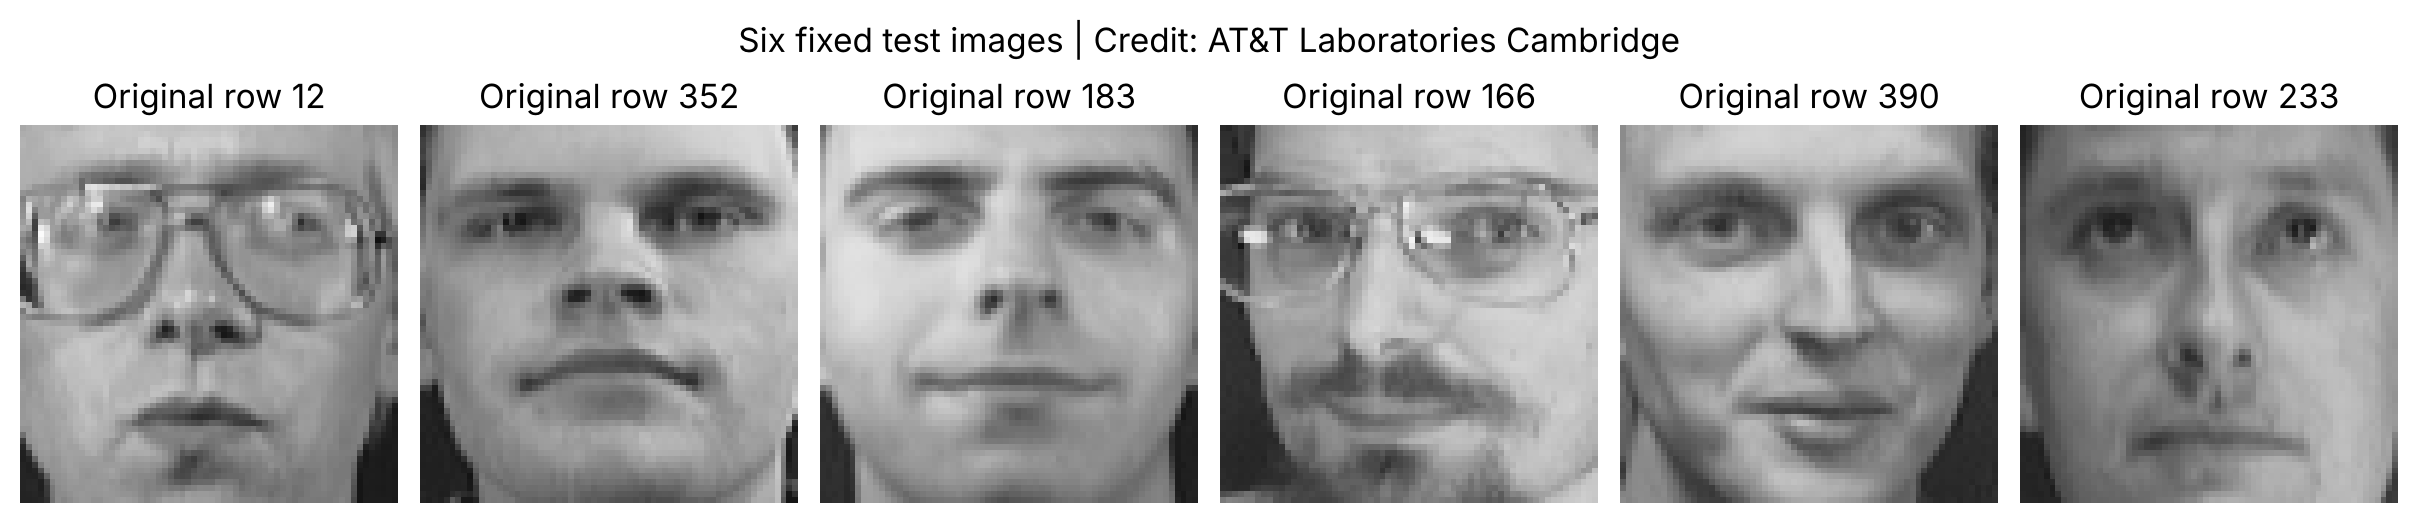

In [14]:
example_positions = np.arange(6)
fig, axes = plt.subplots(1, 6, figsize=(12, 2.5), layout="constrained")
for ax, pos in zip(axes, example_positions):
    ax.imshow(X_test[pos].reshape(64, 64), cmap="gray", vmin=0, vmax=1)
    ax.set_title(f"Original row {test_idx[pos]}")
    ax.axis("off")
fig.suptitle("Six fixed test images | Credit: AT&T Laboratories Cambridge")
fig.savefig(OUT / "original_test_faces.png", dpi=180)
plt.show()

## 3. 让 NMF 学会一套共用的基础图案

这次先用 **40 个图案**，沿用此前预先设定的例子；40 在这里是图案数，和 40 个身份的含义不同。

- `H`：学出的基础图案；每行是一幅图案。
- `W_train`：每张训练照片要使用各个图案多少份。

关键一行是 `nmf.fit_transform(X_train)`：学习只用训练照片。
这里调用现成的 NMF 算法；先弄懂输入和输出，后续再和 Person 4 一起理解算法怎样更新图案。

In [15]:
K = 40
nmf = NMF(n_components=K, init="nndsvda", solver="cd",
          beta_loss="frobenius", max_iter=3000, tol=1e-4,
          random_state=42, alpha_W=0.0, alpha_H=0.0, l1_ratio=0.0)
with warnings.catch_warnings(record=True) as fit_warnings, threadpool_limits(limits=1):
    warnings.simplefilter("always", ConvergenceWarning)
    W_train = nmf.fit_transform(X_train)
H = nmf.components_
assert W_train.shape == (320, K) and H.shape == (K, 4096)
assert W_train.min() >= 0 and H.min() >= 0
print("学到的图案数：", len(H))
print("每张训练照片有", W_train.shape[1], "个图案使用份量。")
print("学习迭代次数：", nmf.n_iter_)
for warning in fit_warnings:
    print("学习警告：", str(warning.message))

学到的图案数： 40
每张训练照片有 40 个图案使用份量。
学习迭代次数： 1472


## 4. 把基础图案画出来

展示前 15 个图案。它们是电脑学出的模式，不是从原照片里选出的 15 张脸。
每幅图按自己的最大值调亮，仅用于看结构；重建仍用原来的 H。
实际图案可能覆盖很大一片脸部，不保证每个图案恰好是一只眼睛或一个鼻子。

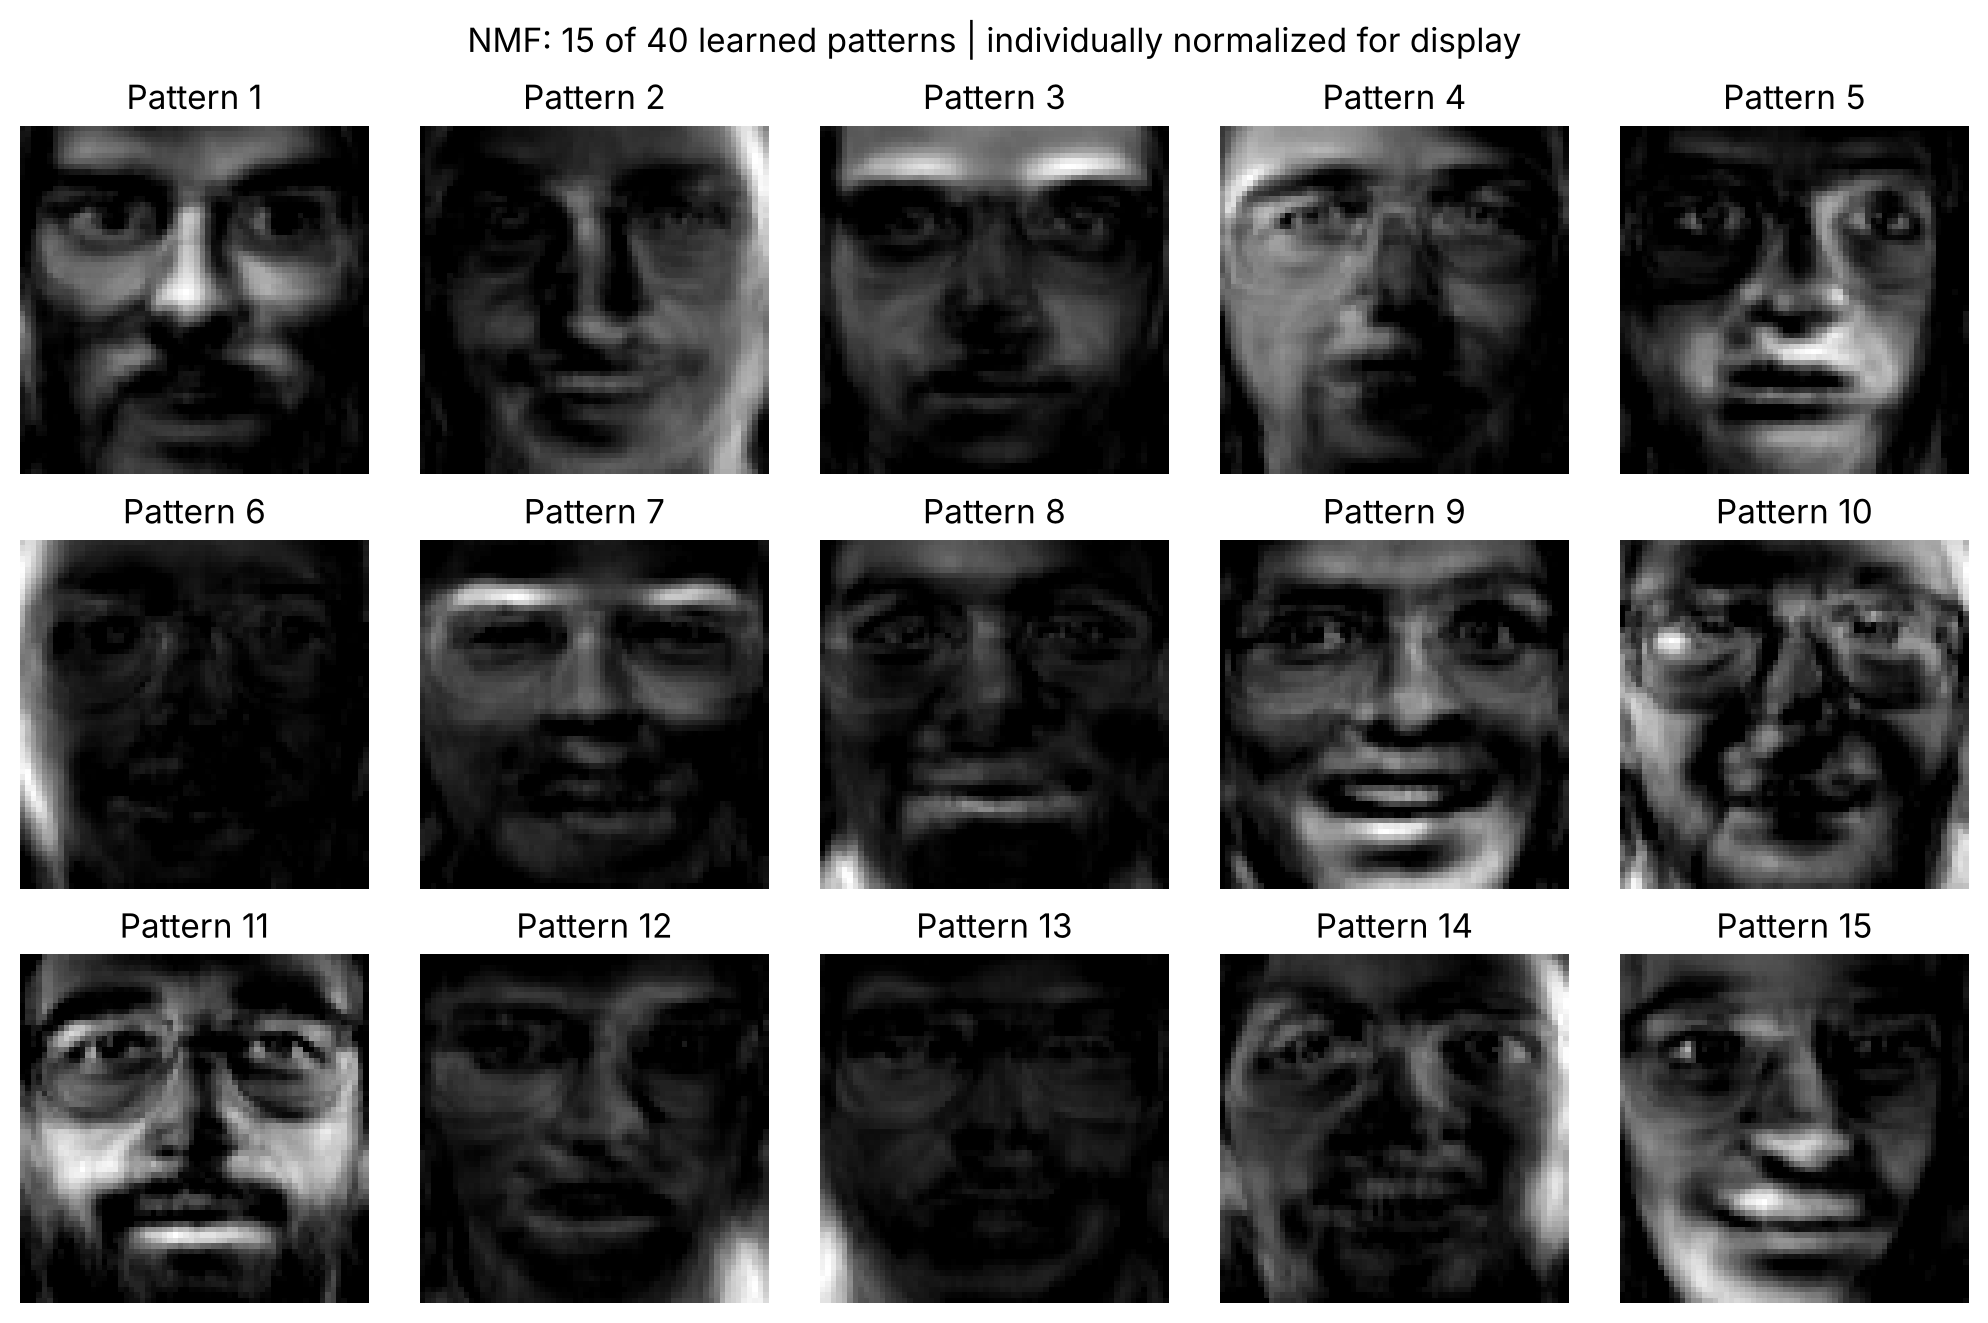

In [16]:
fig, axes = plt.subplots(3, 5, figsize=(10, 6.5), layout="constrained")
for j, ax in enumerate(axes.flat):
    display_pattern = H[j] / max(float(H[j].max()), 1e-12)
    ax.imshow(display_pattern.reshape(64,64), cmap="gray", vmin=0, vmax=1)
    ax.set_title(f"Pattern {j + 1}")
    ax.axis("off")
fig.suptitle("NMF: 15 of 40 learned patterns | individually normalized for display")
fig.savefig(OUT / "nmf_patterns_k40.png", dpi=180)
plt.show()

## 5. 用学到的图案拼回测试照片

`nmf.transform(X_test)`：基础图案 H 已经固定，只计算每张测试照片需要多少份图案。

`W_test @ H`：把图案按这些份量相加。`@` 表示矩阵乘法，在这里完成“按份量组合图案”。

这里的“测试”是看已见过的人在其他照片里能否被重建，没有要求识别身份。

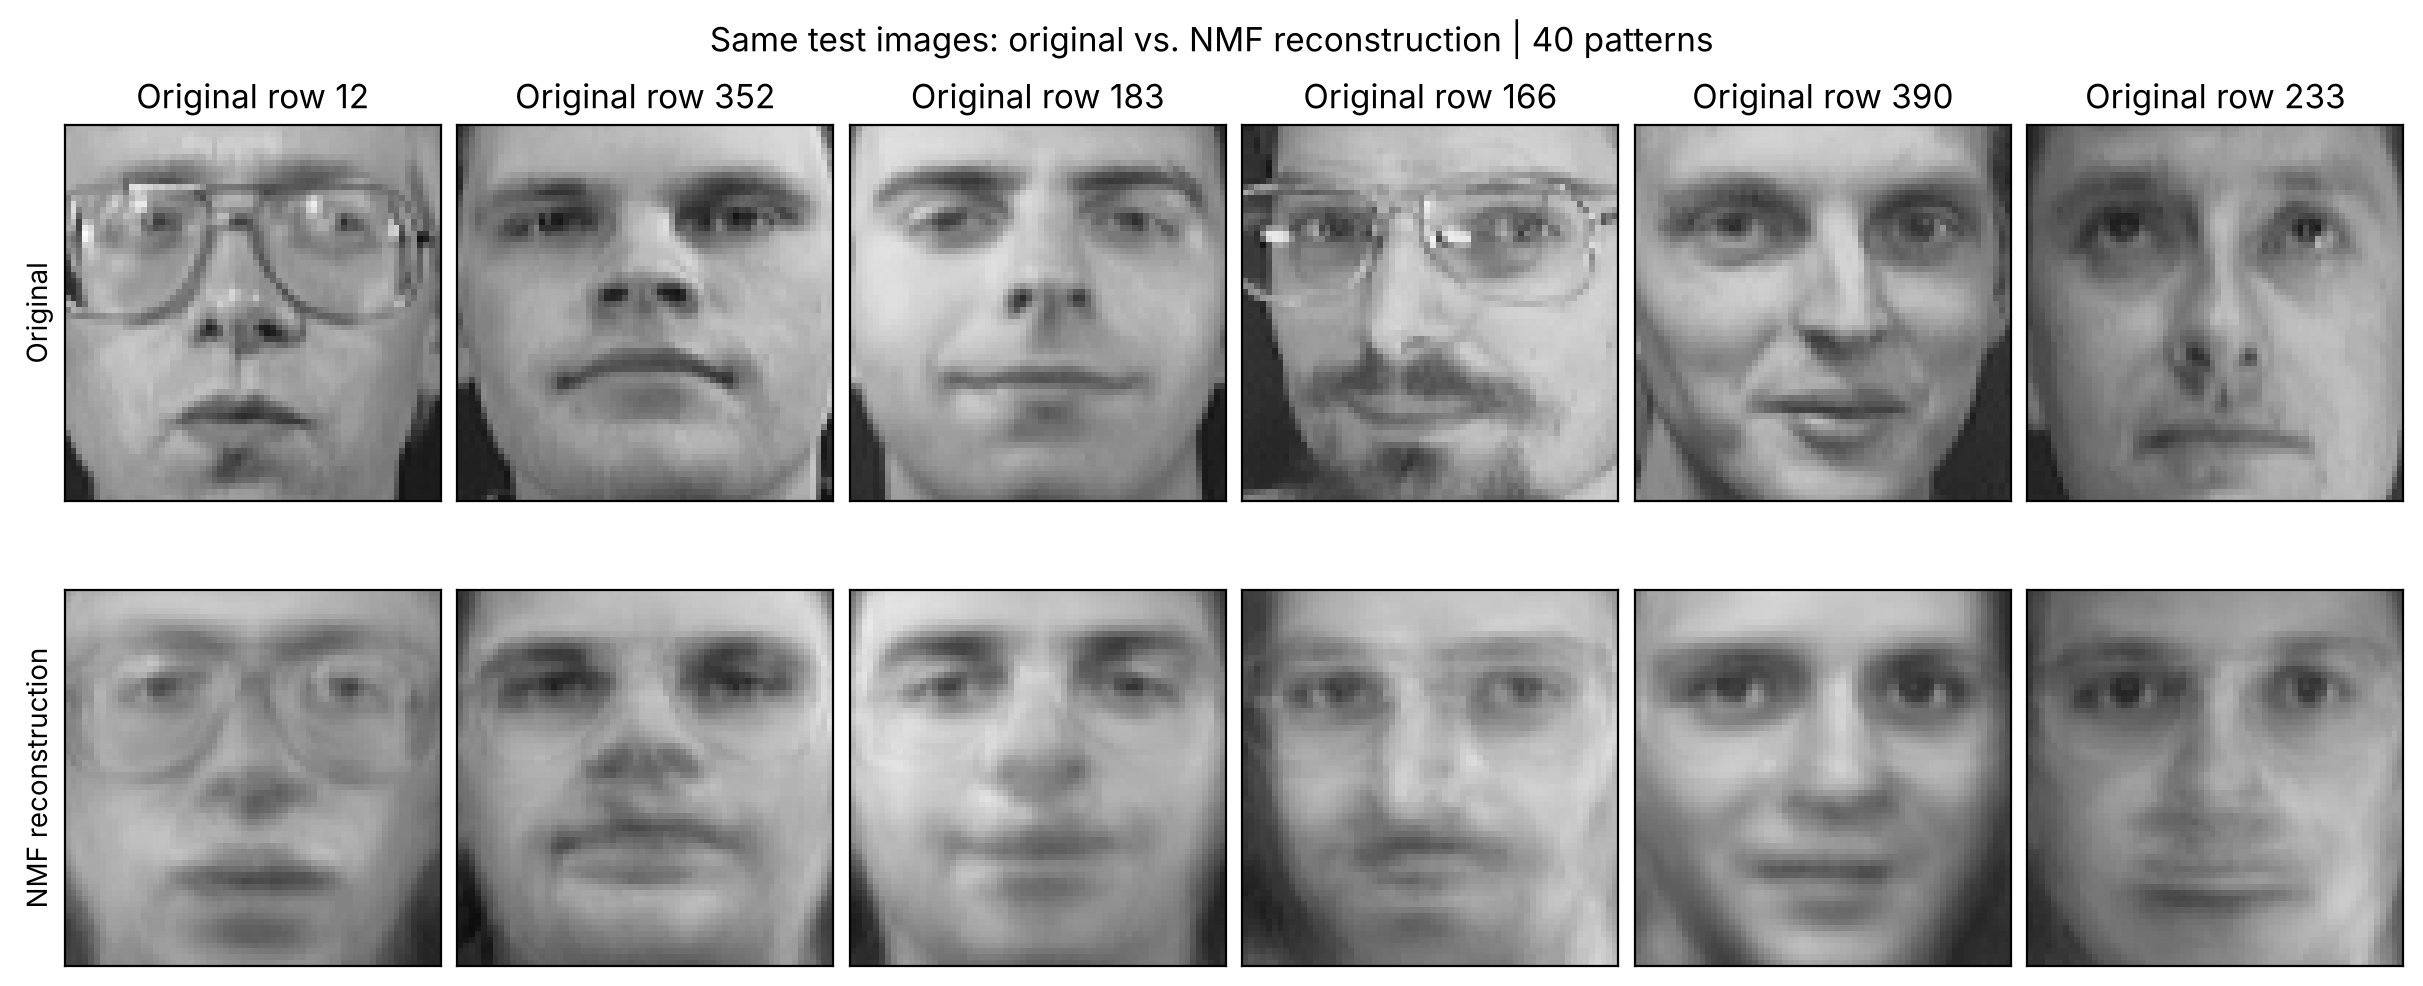

In [17]:
with warnings.catch_warnings(record=True) as transform_warnings, threadpool_limits(limits=1):
    warnings.simplefilter("always", ConvergenceWarning)
    W_test = nmf.transform(X_test)
    reconstructed_train = W_train @ H
    reconstructed_test = W_test @ H
assert W_test.min() >= 0

fig, axes = plt.subplots(2, 6, figsize=(12, 5), layout="constrained")
for col, pos in enumerate(example_positions):
    for row, values in enumerate([X_test, reconstructed_test]):
        ax = axes[row, col]
        ax.imshow(np.clip(values[pos], 0, 1).reshape(64,64), cmap="gray", vmin=0, vmax=1)
        ax.set_xticks([]); ax.set_yticks([])
        if row == 0:
            ax.set_title(f"Original row {test_idx[pos]}")
        if col == 0:
            ax.set_ylabel("Original" if row == 0 else "NMF reconstruction")
fig.suptitle("Same test images: original vs. NMF reconstruction | 40 patterns")
fig.savefig(OUT / "nmf_reconstructions_k40.png", dpi=180)
plt.show()
for warning in transform_warnings:
    print("测试照片编码警告：", str(warning.message))

## 6. 拼得有多像？

对每个小格子，计算原图亮度与重建亮度的差，把差平方，再取所有测试照片所有像素的平均。
这个数字叫 **MSE（均方误差）**；越小，像素越接近。它不是百分比，也不代表识别正确率。

图上显示亮度限制在 [0,1]，误差使用未经裁剪的重建值。PCA 组员也应使用同样定义。

In [18]:
train_mse = float(np.mean((X_train - reconstructed_train)**2))
test_mse = float(np.mean((X_test - reconstructed_test)**2))
assert np.isclose(train_mse, nmf.reconstruction_err_**2 / X_train.size, rtol=1e-6)
with (OUT / "metrics.csv").open("w", newline="") as stream:
    writer = csv.DictWriter(stream, fieldnames=["method", "k", "train_mse", "test_mse"])
    writer.writeheader()
    writer.writerow({"method":"NMF", "k":K, "train_mse":train_mse, "test_mse":test_mse})
np.savez_compressed(OUT / "nmf_arrays_k40.npz", W_train=W_train, W_test=W_test,
                    H=H, train_idx=train_idx, test_idx=test_idx,
                    reconstructed_test=reconstructed_test)
all_warnings = [{"stage":stage,"category":w.category.__name__,"message":str(w.message)}
    for stage, items in [("fit",fit_warnings),("transform",transform_warnings)] for w in items]
metadata = {"source_file":"data/olivetti_preprocessed.npz",
    "source_sha256":hashlib.sha256(data_path.read_bytes()).hexdigest(),
    "input":"Teammate-prepared split, used directly without resplitting or centering",
    "params":nmf.get_params(), "fit_iterations":int(nmf.n_iter_), "warnings":all_warnings,
    "numpy_version":np.__version__, "sklearn_version":sklearn.__version__,
    "example_test_positions":example_positions.tolist(),
    "train_mse":train_mse,"test_mse":test_mse}
(OUT / "run_metadata.json").write_text(json.dumps(metadata, ensure_ascii=False, indent=2))
print(f"训练照片的 MSE：{train_mse:.8f}")
print(f"测试照片的 MSE：{test_mse:.8f}")
print("警告数量：", len(all_warnings))
print("图片和结果已保存到：", OUT.relative_to(ROOT))  # [合并版修改] 打印相对路径；原为 print(..., OUT)，会把运行者电脑上的绝对路径写进保存的输出

训练照片的 MSE：0.00307863
测试照片的 MSE：0.00394635
警告数量： 0
图片和结果已保存到： outputs/team_nmf


你现在先能解释这三件事就好：**训练照片用来学图案；测试照片用这些图案重建；MSE 衡量像素相差多少。**

下一步和组员对齐的是图案数（40）及同样的误差定义。组员的 PCA 也需要只在 X_train 学习，再重建同一份 X_test。

方法参考：[scikit-learn NMF 官方说明](https://scikit-learn.org/stable/modules/generated/sklearn.decomposition.NMF.html)。

---
<a id="part-p4"></a>
# ▌PART P4 — Person 4: NMF theory and analysis  ·  *main part of this notebook*
## Olivetti Faces: nonnegative representations and comparison with PCA

**Main question:** How does NMF represent a face as an additive combination of learned patterns, and what do we gain or lose compared with PCA?

This part explains the model, the optimization, interpretability, and limitations. It reproduces Person 3's NMF settings (Part P3), compares NMF with PCA at the same number of components (building on Part P2), and then checks how far the conclusions depend on the component count, the initialization, and the stopping tolerance. All reported experimental values are computed below.

**Run time.** This part takes roughly 8–9 minutes on one CPU thread; the slow sections are the component-count grid (Section 6.1) and the initialization study (Section 6.2). Setting `QUICK = True` in the setup cell below uses a smaller grid and fewer random starts and takes about half as long. Figures and tables are written to `p4_results/`.

## 1. Shared data and experimental design

Each image has $64\times64=4096$ grayscale pixels. The supplied split contains 320 training images and 80 test images, with eight training and two test images per person. We preserve this split.

NMF uses the original nonnegative intensities. We do **not** subtract a mean before NMF, because that would introduce negative entries. PCA performs its own training-mean centering. Both methods are evaluated in the original pixel space. Identity labels are used only to check the split, not to learn representations.

Besides PCA we use an **uncentered truncated SVD** as a reference: it has no mean term and no sign constraint, like NMF's lack of a mean, but its factors may be negative. Comparing NMF with it separates the cost of the nonnegativity constraint from the effect of the missing mean term.

In [19]:
from pathlib import Path
import hashlib
import json
import platform
import time
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy
import sklearn
from scipy.optimize import nnls
from sklearn.decomposition import NMF, PCA
from sklearn.exceptions import ConvergenceWarning
from threadpoolctl import threadpool_limits

QUICK = False  # True: smaller k-grid and fewer random starts (about half the run time).

DATA_PATH = None  # Optionally replace with Path("/your/path/olivetti_preprocessed.npz").
if DATA_PATH is None:
    candidates = [Path(folder) / "olivetti_preprocessed.npz"
                  for folder in (".", "data", "../data", "upload")]
    DATA_PATH = next((p for p in candidates if p.is_file()), None)
if DATA_PATH is None:
    raise FileNotFoundError("Place olivetti_preprocessed.npz beside this notebook, in data/, or in ../data/.")
DATA_PATH = Path(DATA_PATH)
OUT = Path("p4_results")
OUT.mkdir(exist_ok=True)
T_START = time.time()

with np.load(DATA_PATH, allow_pickle=False) as data:
    X_train = data["X_train"].astype(np.float64)
    X_test = data["X_test"].astype(np.float64)
    y_train, y_test = data["y_train"], data["y_test"]
    train_idx, test_idx = data["train_idx"], data["test_idx"]

assert X_train.shape == (320, 4096) and X_test.shape == (80, 4096)
assert np.isfinite(X_train).all() and np.isfinite(X_test).all()
assert 0 <= X_train.min() <= X_train.max() <= 1
assert 0 <= X_test.min() <= X_test.max() <= 1
assert len(np.intersect1d(train_idx, test_idx)) == 0
assert np.array_equal(np.sort(np.r_[train_idx, test_idx]), np.arange(400))
assert np.array_equal(np.unique(y_train), np.unique(y_test))
assert np.all(np.unique(y_train, return_counts=True)[1] == 8)
assert np.all(np.unique(y_test, return_counts=True)[1] == 2)

K = 40                                   # representation size used by Person 3
K_GRID = [5, 10, 25, 40, 50] if QUICK else [5, 10, 25, 40, 50, 100]   # Person 2's PCA grid plus k = 40
SEEDS = [0, 1] if QUICK else [0, 1, 2, 3, 4]                          # random starts for Section 6.2

def mse(original, reconstruction):
    return float(np.mean((original - reconstruction) ** 2))

plt.rcParams.update({"font.size": 10, "figure.dpi": 110})
print(f"Training: {X_train.shape}; test: {X_test.shape}")
print("40 identities; 8 training and 2 test images per identity.")
print(f"Python {platform.python_version()} | NumPy {np.__version__} | SciPy {scipy.__version__} | "
      f"scikit-learn {sklearn.__version__}")
print(f"QUICK mode: {QUICK}")

Training: (320, 4096); test: (80, 4096)
40 identities; 8 training and 2 test images per identity.
Python 3.13.18 | NumPy 2.5.3 | SciPy 1.18.1 | scikit-learn 1.9.1
QUICK mode: False


## 2. Mathematical formulation

For a nonnegative image matrix $X\in\mathbb{R}_+^{n\times d}$, NMF seeks

$$X\approx WH,\qquad W\in\mathbb{R}_+^{n\times k},\quad H\in\mathbb{R}_+^{k\times d}.$$

| Matrix | Meaning | Training shape at $k=40$ |
|---|---|---|
| $X$ | Original images, one image per row | $320\times4096$ |
| $W$ | Amount of each pattern used by each image | $320\times40$ |
| $H$ | Shared patterns, one pattern per row | $40\times4096$ |

One reconstructed face is

$$\hat x_i=\sum_{r=1}^{k}W_{ir}H_{r,:}.$$

Each coefficient and pattern is nonnegative: the model builds an image by **adding brightness patterns**, without cancellation by negative terms. The number 40 is the chosen representation dimension; it does not assign one component to each of the 40 people.

### Objective used in our experiment

$$\min_{W\geq0,H\geq0} f(W,H)
=\frac12\|X-WH\|_F^2
=\frac12\sum_{i=1}^{n}\sum_{j=1}^{d}
\left(X_{ij}-\sum_{r=1}^{k}W_{ir}H_{rj}\right)^2.$$

The Frobenius norm sums squared pixel errors. No sparsity or other regularization penalty is included in this experiment. For evaluation we use

$$\operatorname{MSE}(X,\hat X)=\frac{\|X-\hat X\|_F^2}{nd}.$$

MSE is a per-pixel squared error, not recognition accuracy or a percentage. The factor $1/2$ in the optimization objective simplifies derivatives without changing the minimizer.

## 3. Optimization: how are the patterns learned?

With $H$ fixed, the problem is a convex nonnegative least-squares problem in $W$; with $W$ fixed, it is convex in $H$. However, it is **not jointly convex** in both. We alternate updates and do not claim a globally optimal factorization. Vavasis (2008) shows that exact NMF is NP-hard, so we do not expect any practical solver to come with a global-optimality guarantee.

The gradients are

$$\nabla_W f=(WH-X)H^\top,\qquad
\nabla_H f=W^\top(WH-X).$$

Our implementation uses **coordinate descent** (`solver="cd"`), rather than the multiplicative updates of Lee and Seung (2001); coordinate-descent updates of this kind are studied by Cichocki and Phan (2009). For intuition, hold all entries except one $W_{ir}$ fixed. The objective is a one-variable quadratic, with curvature $a_r=\sum_jH_{rj}^2$. Its constrained minimizer is

$$W_{ir}\leftarrow\max\left(0,\;W_{ir}-\frac{(\nabla_W f)_{ir}}{a_r}\right),\qquad a_r>0.$$

Similarly, holding other entries fixed gives

$$H_{rj}\leftarrow\max\left(0,\;H_{rj}-\frac{(\nabla_H f)_{rj}}{\sum_i W_{ir}^2}\right)$$

when the denominator is positive. A zero denominator means the objective is independent of that coordinate while the other factor is fixed. Each gradient is evaluated at the current factors; these are coordinate updates, not simultaneous matrix updates.

Conceptually:

```text
Initialize nonnegative W and H
Repeat:
    Update coordinates of W while H is fixed
    Update coordinates of H while W is fixed
    Check the solver's stopping criterion
Return W and H
```

`nndsvda` uses an SVD-based nonnegative initialization and fills its zero entries with the input mean. The tolerance controls the numerical stopping criterion; reaching it does not prove global optimality. The parameter meanings follow the [scikit-learn NMF API](https://scikit-learn.org/stable/modules/generated/sklearn.decomposition.NMF.html).

### What happens to a test image?

After training, $H$ is fixed. Test encoding solves for nonnegative coefficients only:

$$W_{\text{test}}\approx\arg\min_{W\geq0}\|X_{\text{test}}-WH\|_F^2.$$

`transform` estimates these coefficients; it does not refit the shared patterns on the test images.

In [20]:
# Person 3's model, precision, and thread limit.
P3_PARAMS = dict(init="nndsvda", solver="cd", beta_loss="frobenius", max_iter=3000, tol=1e-4,
                 random_state=42, alpha_W=0.0, alpha_H=0.0, l1_ratio=0.0)
nmf = NMF(n_components=K, **P3_PARAMS)
with warnings.catch_warnings(record=True) as fit_warnings, threadpool_limits(limits=1):
    warnings.simplefilter("always", ConvergenceWarning)
    W_train = nmf.fit_transform(X_train)
H = nmf.components_.copy()
with warnings.catch_warnings(record=True) as test_warnings, threadpool_limits(limits=1):
    warnings.simplefilter("always", ConvergenceWarning)
    W_test = nmf.transform(X_test)

Xn_train = W_train @ H
Xn_test = W_test @ H
assert W_train.shape == (320, K) and H.shape == (K, 4096)
assert W_test.shape == (80, K)
assert min(W_train.min(), H.min(), W_test.min()) >= 0
assert np.array_equal(nmf.components_, H)
print(f"Training iterations: {nmf.n_iter_} / {nmf.max_iter}")
print(f"Training warnings: {len(fit_warnings)}; test-encoding warnings: {len(test_warnings)}")
for stage, items in [("training", fit_warnings), ("test encoding", test_warnings)]:
    for item in items:
        print(f"{stage}: {item.message}")

def fit_nmf(k, **overrides):
    # Fit NMF on the training images, then encode the test images with H fixed.
    model = NMF(n_components=k, **{**P3_PARAMS, **overrides})
    with warnings.catch_warnings(record=True) as caught, threadpool_limits(limits=1):
        warnings.simplefilter("always", ConvergenceWarning)
        W_tr = model.fit_transform(X_train)
        W_te = model.transform(X_test)
    hit_cap = any(issubclass(w.category, ConvergenceWarning) for w in caught)
    return {"k": k, "iters": int(model.n_iter_), "hit_cap": hit_cap,
            "train_mse": mse(X_train, W_tr @ model.components_),
            "test_mse": mse(X_test, W_te @ model.components_)}

base = {"k": K, "iters": int(nmf.n_iter_), "hit_cap": bool(fit_warnings or test_warnings),
        "train_mse": mse(X_train, Xn_train), "test_mse": mse(X_test, Xn_test)}

Training iterations: 1472 / 3000
Training warnings: 0; test-encoding warnings: 0


### 3.1 Evidence that the optimization behaves as described

Two checks, one for each stage of the pipeline.

**(a) Test encoding.** For fixed $H$ the encoding of each test image is a small convex nonnegative least-squares problem that SciPy can solve exactly. If `transform` is accurate, its reconstruction error should match the exact solution.

**(b) Training convergence.** Because the initialization and the coordinate order are deterministic here, refitting with a smaller `max_iter` retraces the same path. Recording the training MSE at several stopping points shows how the objective falls. The dashed line is the Eckart–Young bound: no rank-40 factorization of any kind, nonnegative or not, can have a lower training error than the truncated SVD of $X$, so NMF can approach this line but never cross it.

Test MSE with sklearn transform: 0.00394635
Test MSE with exact NNLS:        0.00394635
Difference: 7.83e-10; largest coefficient difference: 4.00e-04


 Sweeps  Train MSE
      5 0.00655220
     10 0.00488980
     20 0.00406661
     50 0.00344289
    100 0.00324261
    200 0.00315733
    400 0.00311760
    800 0.00308934
   1472 0.00307863
Eckart-Young lower bound on training MSE (rank 40): 0.00282031


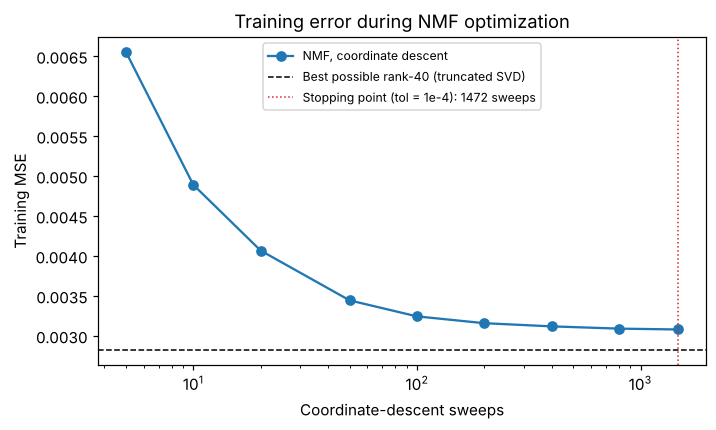

In [21]:
# (a) Exact nonnegative least squares for each test image, with H fixed.
W_exact = np.vstack([nnls(H.T, x, maxiter=20000)[0] for x in X_test])
mse_transform = mse(X_test, Xn_test)
mse_exact = mse(X_test, W_exact @ H)
print(f"Test MSE with sklearn transform: {mse_transform:.8f}")
print(f"Test MSE with exact NNLS:        {mse_exact:.8f}")
print(f"Difference: {mse_transform - mse_exact:.2e}; largest coefficient difference: "
      f"{np.abs(W_test - W_exact).max():.2e}")
assert -1e-12 <= mse_transform - mse_exact < 1e-7   # exact can never be worse; transform is accurate

# (b) Training MSE versus the number of coordinate-descent sweeps.
singular_values = np.linalg.svd(X_train, compute_uv=False)
lower_bound_train_mse = float((singular_values[K:] ** 2).sum() / X_train.size)   # Eckart-Young
checkpoints = [5, 10, 20, 50, 100, 200, 400, 800, base["iters"]]
curve = []
for sweeps in checkpoints:
    with warnings.catch_warnings(), threadpool_limits(limits=1):
        warnings.simplefilter("ignore")
        partial = NMF(n_components=K, **{**P3_PARAMS, "max_iter": sweeps})
        W_partial = partial.fit_transform(X_train)
    curve.append(mse(X_train, W_partial @ partial.components_))
convergence = pd.DataFrame({"Sweeps": checkpoints, "Train MSE": curve})
assert np.isclose(curve[-1], base["train_mse"], rtol=1e-6)          # same path as the full run
assert np.all(np.diff(curve) < 0) and curve[-1] >= lower_bound_train_mse
print(convergence.to_string(index=False, float_format=lambda v: f"{v:.8f}"))
print(f"Eckart-Young lower bound on training MSE (rank {K}): {lower_bound_train_mse:.8f}")

fig, ax = plt.subplots(figsize=(6.4, 3.8), layout="constrained")
ax.plot(checkpoints, curve, "o-", label="NMF, coordinate descent")
ax.axhline(lower_bound_train_mse, color="k", ls="--", lw=1, label="Best possible rank-40 (truncated SVD)")
ax.axvline(base["iters"], color="C3", ls=":", lw=1, label=f"Stopping point (tol = 1e-4): {base['iters']} sweeps")
ax.set(xscale="log", xlabel="Coordinate-descent sweeps", ylabel="Training MSE",
       title="Training error during NMF optimization")
ax.legend(fontsize=8)
fig.savefig(OUT / "04_convergence.png", dpi=160, bbox_inches="tight")
plt.show()

The test encoding is solved essentially exactly, so differences between the methods below are not an artifact of imprecise test-time coefficients. The training error falls steeply during the first hundred or so sweeps and then slowly. It stops at the tolerance, not at the end of the curve: the stricter-tolerance run in Section 6.2 reaches a lower error. The reported NMF errors are therefore *upper bounds* on what this model class can achieve on these data, and they stay above the unconstrained rank-40 bound.

## 4. Interpretability: what is actually being added?

PCA reconstructs a face as $\hat x=\mu+zV_k^\top$, where the mean $\mu$ and orthonormal directions $V_k$ come from the training set. Both coefficients and directions can have either sign. NMF instead uses a nonnegative dictionary and nonnegative coefficients.

| Property | PCA | NMF |
|---|---|---|
| Representation | Signed changes around a mean face | Additive brightness patterns |
| Basis constraint | Orthogonal directions | Nonnegative patterns; overlap allowed |
| Component order | Descending explained variance | No intrinsic importance ranking |
| Natural interpretation | Directions of variation | Contributions to a reconstruction |

The plot below shows the first eight stored components of each fitted model. NMF patterns are individually divided by their maxima **for display only**. PCA components share a symmetric color scale: red is positive and blue is negative. Columns do not match corresponding components across the two methods.

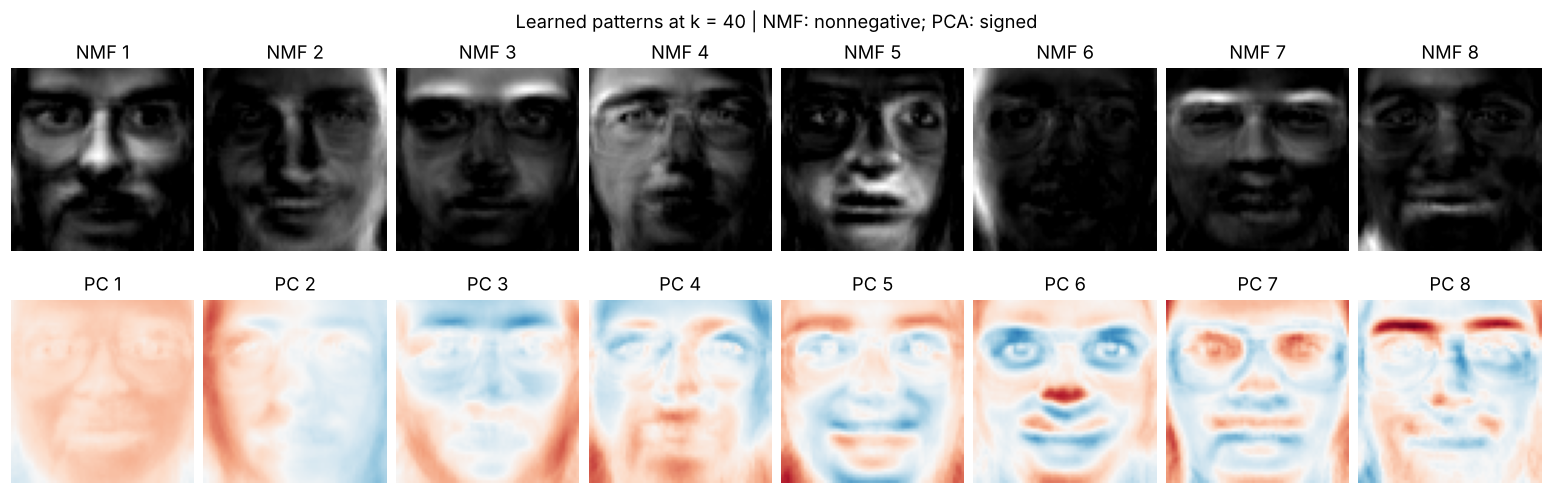

In [22]:
with threadpool_limits(limits=1):
    pca = PCA(n_components=K, svd_solver="full")
    Z_train = pca.fit_transform(X_train)
    Z_test = pca.transform(X_test)
Xp_train = pca.inverse_transform(Z_train)
Xp_test = pca.inverse_transform(Z_test)

fig, axes = plt.subplots(2, 8, figsize=(14, 4.5), layout="constrained")
pca_limit = np.abs(pca.components_[:8]).max()
for j in range(8):
    axes[0, j].imshow((H[j] / max(H[j].max(), 1e-12)).reshape(64, 64),
                      cmap="gray", vmin=0, vmax=1)
    axes[0, j].set_title(f"NMF {j+1}")
    axes[1, j].imshow(pca.components_[j].reshape(64, 64), cmap="RdBu_r",
                      vmin=-pca_limit, vmax=pca_limit)
    axes[1, j].set_title(f"PC {j+1}")
for ax in axes.flat:
    ax.axis("off")
fig.suptitle("Learned patterns at k = 40 | NMF: nonnegative; PCA: signed")
fig.savefig(OUT / "01_components.png", dpi=160, bbox_inches="tight")
plt.show()

**Visual interpretation.** The displayed NMF patterns remain largely face-like rather than isolated anatomical parts. NMF 3 emphasizes the forehead, while NMF 6 has a bright strip along the left image boundary; both still contain broader facial structure. Other patterns distribute intensity across the eyes, cheeks, and mouth. In PCA, PC 1 shows a broad brightness pattern, PC 2 contrasts the two sides of the image, and later components contain alternating positive and negative regions. These observations support different ways of representing brightness, but do not establish that NMF has discovered independent facial parts.

Nonnegativity guarantees an additive explanation, but it does not guarantee isolated eyes, noses, or mouths. A component can combine several regions or cover much of the face. This model has no explicit penalty encouraging spatial locality or sparsity. Lee and Seung (1999) report parts-based face representations; the Olivetti patterns here are much broader, so we do not reproduce a clean parts-based result in this experiment.

### 4.1 Quantifying "broad and overlapping"

The visual impression can be measured. Hoyer's sparsity (2004) of a vector $v\in\mathbb{R}^d$ is $\bigl(\sqrt d-\|v\|_1/\|v\|_2\bigr)/(\sqrt d-1)$: it equals 0 when all entries are equal and 1 when only one entry is nonzero. For PCA we apply it to absolute loadings, which is only a descriptive reference because signed loadings can cancel. We also count exact zeros and how many patterns each training image actually uses.

                                    Quantity          NMF PCA (absolute loadings)
      Mean Hoyer sparsity of the 40 patterns        0.317                   0.221
                     Range of Hoyer sparsity 0.22 to 0.52            0.05 to 0.28
                            Exact zeros in H        18.7%          not applicable
                 Exact zeros in W (training)        25.5%          not applicable
Mean nonzero coefficients per training image   29.8 of 40                40 of 40


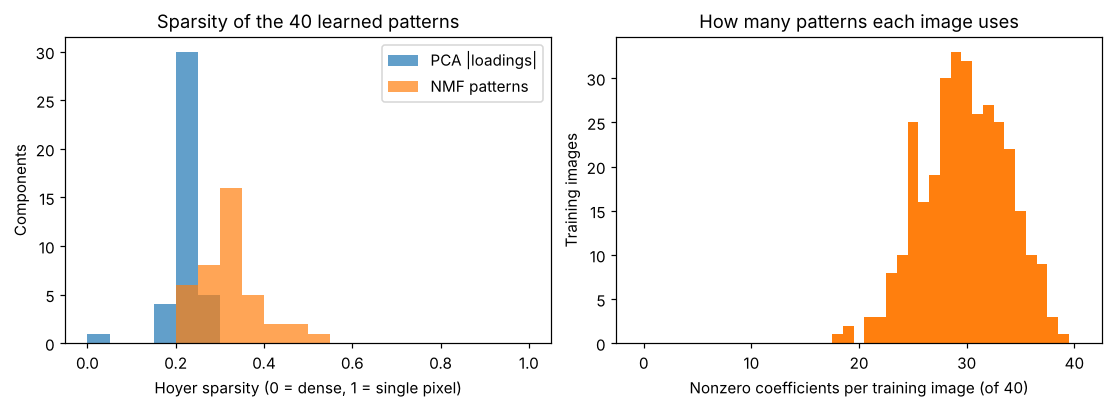

In [23]:
def hoyer(v):
    n = v.size
    return float((np.sqrt(n) - np.abs(v).sum() / max(np.sqrt((v ** 2).sum()), 1e-12)) / (np.sqrt(n) - 1))

hoyer_nmf = np.array([hoyer(row) for row in H])
hoyer_pca = np.array([hoyer(np.abs(row)) for row in pca.components_])
active_per_image = (W_train > 0).sum(axis=1)
sparsity = pd.DataFrame([
    ("Mean Hoyer sparsity of the 40 patterns", f"{hoyer_nmf.mean():.3f}", f"{hoyer_pca.mean():.3f}"),
    ("Range of Hoyer sparsity", f"{hoyer_nmf.min():.2f} to {hoyer_nmf.max():.2f}",
     f"{hoyer_pca.min():.2f} to {hoyer_pca.max():.2f}"),
    ("Exact zeros in H", f"{100 * (H == 0).mean():.1f}%", "not applicable"),
    ("Exact zeros in W (training)", f"{100 * (W_train == 0).mean():.1f}%", "not applicable"),
    ("Mean nonzero coefficients per training image", f"{active_per_image.mean():.1f} of {K}", f"{K} of {K}"),
], columns=["Quantity", "NMF", "PCA (absolute loadings)"])
print(sparsity.to_string(index=False))
sparsity.to_csv(OUT / "sparsity_k40.csv", index=False)

fig, axes = plt.subplots(1, 2, figsize=(10, 3.6), layout="constrained")
bins = np.linspace(0, 1, 21)
axes[0].hist(hoyer_pca, bins=bins, alpha=0.7, label="PCA |loadings|")
axes[0].hist(hoyer_nmf, bins=bins, alpha=0.7, label="NMF patterns")
axes[0].set(xlabel="Hoyer sparsity (0 = dense, 1 = single pixel)", ylabel="Components",
            title="Sparsity of the 40 learned patterns")
axes[0].legend()
axes[1].hist(active_per_image, bins=np.arange(0, K + 2) - 0.5, color="C1")
axes[1].set(xlabel="Nonzero coefficients per training image (of 40)", ylabel="Training images",
            title="How many patterns each image uses")
fig.savefig(OUT / "05_sparsity.png", dpi=160, bbox_inches="tight")
plt.show()

NMF patterns are somewhat sparser than the absolute PCA loadings, but all values are far from 1: the patterns are dense, overlapping images, and a typical image draws on roughly three quarters of the 40 patterns. This is the quantitative counterpart of the visual finding. Nonnegativity alone does not produce a small set of localized parts.

### An example face as a sum of contributions

For the first test image, the contribution of component $r$ is $c_r=W_{0r}H_{r,:}$. We rank contributions by their total brightness $\sum_jc_{rj}$, not by the raw coefficient alone. This ranking is unchanged if a pattern is rescaled and its coefficient is inversely rescaled. It is a display ordering, not a measure of causal importance.

In the top row, each of the three largest contributions is scaled to its own maximum so its structure is visible, and the bar chart shows what share of the image's total brightness each of the 40 contributions supplies. The bottom row shows cumulative sums on the same $[0,1]$ brightness range as the original. All 40 contributions are used in the full reconstruction.

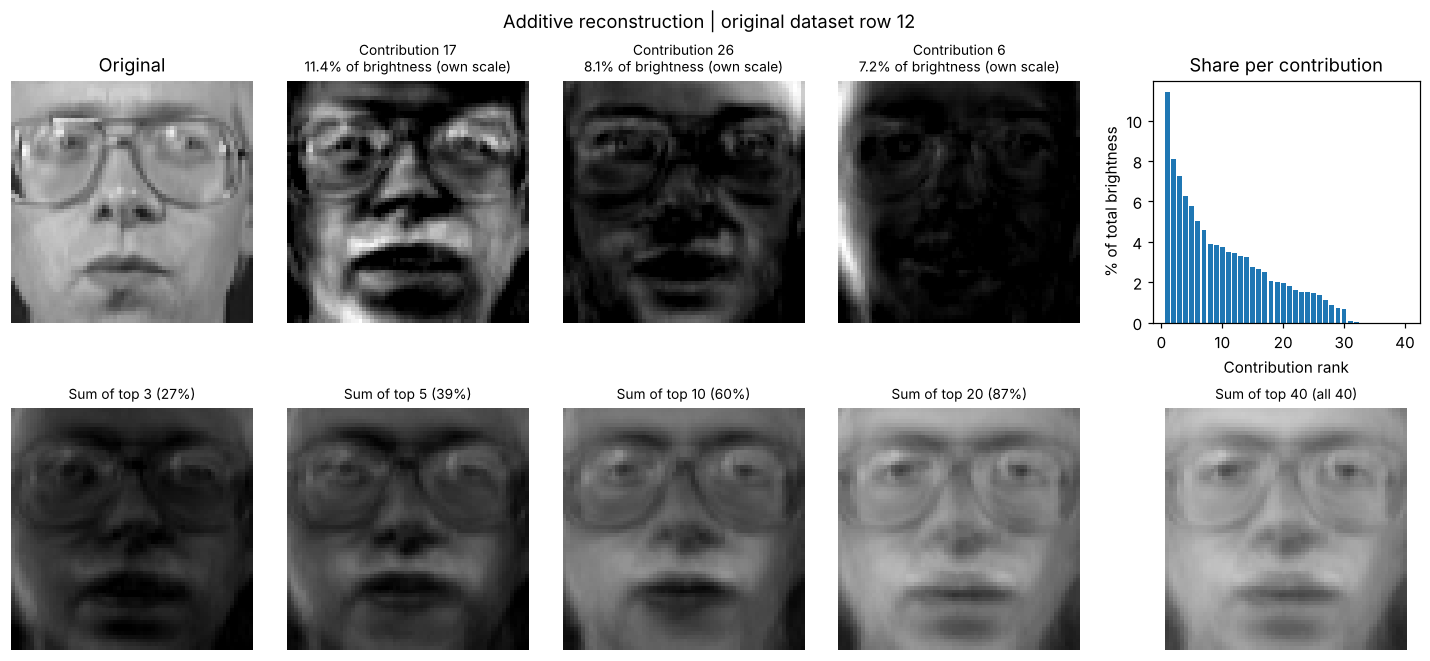

Sum of all contributions equals W_test @ H: True
Largest single share: 11.4%; top 3: 26.7%; top 10: 59.9%


In [24]:
example = 0  # Fixed in advance; not selected for reconstruction quality.
contributions = W_test[example, :, None] * H
totals = contributions.sum(axis=1)
order = np.argsort(-totals, kind="stable")
share = totals[order] / totals.sum()
ordered = contributions[order]
partial_sums = np.cumsum(ordered, axis=0)
assert np.allclose(partial_sums[-1], Xn_test[example])

fig = plt.figure(figsize=(13, 5.9), layout="constrained")
grid_spec = fig.add_gridspec(2, 5)
ax = fig.add_subplot(grid_spec[0, 0])
ax.imshow(X_test[example].reshape(64, 64), cmap="gray", vmin=0, vmax=1)
ax.set_title("Original"); ax.axis("off")
for j in range(3):
    ax = fig.add_subplot(grid_spec[0, j + 1])
    ax.imshow((ordered[j] / ordered[j].max()).reshape(64, 64), cmap="gray", vmin=0, vmax=1)
    ax.set_title(f"Contribution {order[j]+1}\n{100*share[j]:.1f}% of brightness (own scale)", fontsize=9)
    ax.axis("off")
ax = fig.add_subplot(grid_spec[0, 4])
ax.bar(np.arange(1, K + 1), 100 * share, color="C0")
ax.set(xlabel="Contribution rank", ylabel="% of total brightness", title="Share per contribution")
for col, n in enumerate([3, 5, 10, 20, 40]):
    ax = fig.add_subplot(grid_spec[1, col])
    ax.imshow(np.clip(partial_sums[n - 1], 0, 1).reshape(64, 64), cmap="gray", vmin=0, vmax=1)
    ax.set_title(f"Sum of top {n}" + (f" ({100*share[:n].sum():.0f}%)" if n < K else " (all 40)"), fontsize=9)
    ax.axis("off")
fig.suptitle(f"Additive reconstruction | original dataset row {test_idx[example]}")
fig.savefig(OUT / "02_additive_reconstruction.png", dpi=160, bbox_inches="tight")
plt.show()
print("Sum of all contributions equals W_test @ H:",
      np.allclose(contributions.sum(axis=0), Xn_test[example]))
print(f"Largest single share: {100*share[0]:.1f}%; top 3: {100*share[:3].sum():.1f}%; "
      f"top 10: {100*share[:10].sum():.1f}%")

No single contribution dominates: even the largest supplies only a modest share of the image's brightness, and the face emerges only as many broad, face-like patterns accumulate. The three ranked first are themselves dense and face-like, which is expected because ranking by total brightness favors broad patterns.

The partial sums are darker because only some nonnegative contributions have been included. Their pixel values cannot decrease as more contributions are added. However, their error relative to the original need not decrease at every step: addition can also overshoot a pixel's true value. The final image is an approximation, not an exact decomposition of the original.

## 5. Reconstruction quality: a matched comparison

All models use the same 320 training images, the same 80 test images, and **40 components**. Errors use raw reconstructions, without clipping. Images are clipped to $[0,1]$ only for display. This matches the team's existing error definition.

Equal component counts make this a useful practical comparison, but the model classes still differ: PCA also stores a mean face, so a 40-component PCA stores 41 images, whereas this NMF has no mean term. To see how much that matters we add two references: **PCA with 39 components plus the mean** (40 stored images, like NMF) and an **uncentered truncated SVD with 40 components** (no mean, signed factors). By the Eckart–Young theorem the latter is the best possible rank-40 approximation of the training matrix, so NMF's training error can never fall below it.

In [25]:
# Uncentered truncated SVD: best rank-K approximation without a mean term.
_, _, Vt = np.linalg.svd(X_train, full_matrices=False)
V_k = Vt[:K]
Xs_train = (X_train @ V_k.T) @ V_k
Xs_test = (X_test @ V_k.T) @ V_k
assert np.isclose(mse(X_train, Xs_train), lower_bound_train_mse)

# PCA with one fewer component plus the mean: also 40 stored images.
with threadpool_limits(limits=1):
    pca39 = PCA(n_components=K - 1, svd_solver="full").fit(X_train)
Xq_train = pca39.inverse_transform(pca39.transform(X_train))
Xq_test = pca39.inverse_transform(pca39.transform(X_test))

results = pd.DataFrame([
    {"Method": "PCA", "Components": K, "Mean term": "yes",
     "Train MSE": mse(X_train, Xp_train), "Test MSE": mse(X_test, Xp_test)},
    {"Method": "PCA (39 components + mean)", "Components": K - 1, "Mean term": "yes",
     "Train MSE": mse(X_train, Xq_train), "Test MSE": mse(X_test, Xq_test)},
    {"Method": "Uncentered SVD", "Components": K, "Mean term": "no",
     "Train MSE": mse(X_train, Xs_train), "Test MSE": mse(X_test, Xs_test)},
    {"Method": "NMF", "Components": K, "Mean term": "no",
     "Train MSE": mse(X_train, Xn_train), "Test MSE": mse(X_test, Xn_test)},
])
pca_test_mse = results.loc[0, "Test MSE"]
nmf_test_mse = results.loc[3, "Test MSE"]
results["Test MSE vs PCA (%)"] = 100 * (results["Test MSE"] / pca_test_mse - 1)
assert np.isclose(nmf.reconstruction_err_**2 / X_train.size, mse(X_train, Xn_train), rtol=1e-6)
print(results.to_string(index=False, float_format=lambda v: f"{v:.8f}"))
print(f"\nNMF minus PCA test MSE: {nmf_test_mse - pca_test_mse:+.8f} "
      f"({100*(nmf_test_mse/pca_test_mse - 1):+.2f}%)")
results.to_csv(OUT / "comparison_k40.csv", index=False)

# Cross-check against Person 3's saved NMF values (8 decimals) -- informational, not a hard assertion.
P3_REPORTED = {"train_mse": 0.00307863, "test_mse": 0.00394635, "iters": 1472}
p3_check = {name: (abs(base[name] - value) <= 6e-9 if name != "iters" else base[name] == value)
            for name, value in P3_REPORTED.items()}
print("Matches Person 3's reported values (train MSE, test MSE, iterations):", p3_check)

                    Method  Components Mean term  Train MSE   Test MSE  Test MSE vs PCA (%)
                       PCA          40       yes 0.00279609 0.00365816           0.00000000
PCA (39 components + mean)          39       yes 0.00285099 0.00369587           1.03082770
            Uncentered SVD          40        no 0.00282031 0.00365797          -0.00529959
                       NMF          40        no 0.00307863 0.00394635           7.87804153

NMF minus PCA test MSE: +0.00028819 (+7.88%)
Matches Person 3's reported values (train MSE, test MSE, iterations): {'train_mse': True, 'test_mse': True, 'iters': True}


Mean paired difference (NMF - PCA): 0.000288; 95% bootstrap CI [0.000233, 0.000344]
PCA has lower error on 74 of 80 test images; NMF on 6.


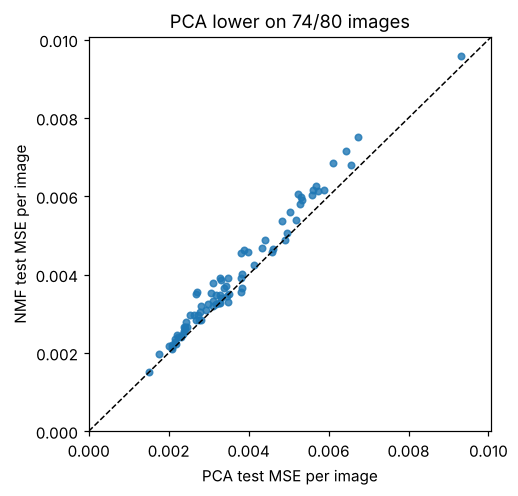

In [26]:
# Paired, per-image comparison on the 80 test images.
err_pca = ((X_test - Xp_test) ** 2).mean(axis=1)
err_nmf = ((X_test - Xn_test) ** 2).mean(axis=1)
diff = err_nmf - err_pca
rng = np.random.default_rng(0)
boot = np.array([diff[rng.integers(0, len(diff), len(diff))].mean() for _ in range(10_000)])
ci_low, ci_high = np.percentile(boot, [2.5, 97.5])
n_pca_better = int((diff > 0).sum())
print(f"Mean paired difference (NMF - PCA): {diff.mean():.6f}; 95% bootstrap CI [{ci_low:.6f}, {ci_high:.6f}]")
print(f"PCA has lower error on {n_pca_better} of {len(diff)} test images; NMF on {len(diff) - n_pca_better}.")

fig, ax = plt.subplots(figsize=(4.6, 4.4), layout="constrained")
lim = max(err_pca.max(), err_nmf.max()) * 1.05
ax.scatter(err_pca, err_nmf, s=18, alpha=0.8)
ax.plot([0, lim], [0, lim], "k--", lw=1)
ax.set(xlim=(0, lim), ylim=(0, lim), xlabel="PCA test MSE per image", ylabel="NMF test MSE per image",
       title=f"PCA lower on {n_pca_better}/80 images")
fig.savefig(OUT / "06_paired_errors.png", dpi=160, bbox_inches="tight")
plt.show()

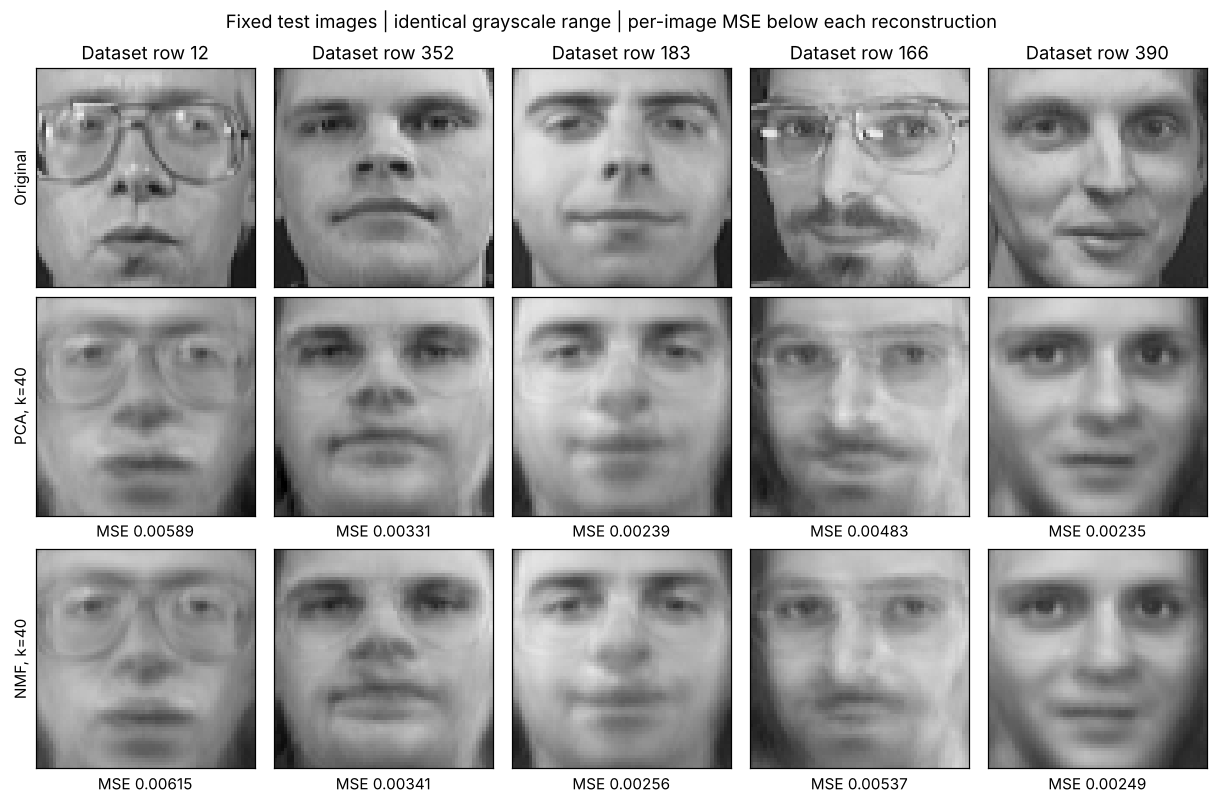

NMF per-image MSE relative to PCA for the five images: {12: '+4.4%', 352: '+3.2%', 183: '+7.3%', 166: '+11.2%', 390: '+5.9%'}


In [27]:
# Keep the first five test images, as in the team's PCA analysis.
fig, axes = plt.subplots(3, 5, figsize=(11, 7.2), layout="constrained")
five_gap = []
for col in range(5):
    five_gap.append(err_nmf[col] / err_pca[col] - 1)
    for row, (name, values) in enumerate([
            ("Original", X_test), ("PCA, k=40", Xp_test), ("NMF, k=40", Xn_test)]):
        ax = axes[row, col]
        ax.imshow(np.clip(values[col], 0, 1).reshape(64, 64), cmap="gray", vmin=0, vmax=1)
        ax.set_xticks([])
        ax.set_yticks([])
        if row == 0:
            ax.set_title(f"Dataset row {test_idx[col]}")
        else:
            ax.set_xlabel(f"MSE {(err_pca if row == 1 else err_nmf)[col]:.5f}")
        if col == 0:
            ax.set_ylabel(name)
fig.suptitle("Fixed test images | identical grayscale range | per-image MSE below each reconstruction")
fig.savefig(OUT / "03_matched_reconstructions.png", dpi=160, bbox_inches="tight")
plt.show()
print("NMF per-image MSE relative to PCA for the five images:",
      {int(test_idx[c]): f"{100*g:+.1f}%" for c, g in enumerate(five_gap)})

**Results and interpretation.** At 40 components PCA has the lower training and test error (see the table above for the exact values). The additional references locate the source of the difference. The uncentered SVD, which has no mean term, reaches essentially the same test error as PCA, and PCA with 39 components plus the mean still beats NMF. So NMF's extra error is not explained by the missing mean term: it reflects the nonnegativity constraint together with the fact that coordinate descent stops at a local solution (Section 6.2). NMF's training error also stays above the Eckart–Young bound, as it must.

The paired comparison shows that the difference is not driven by a few unusual images: PCA has the lower error on most of the 80 test images, and the bootstrap interval for the mean difference excludes zero. The interval describes variation across these test images only; all identities appear in both splits, so it does not capture variation across people or across different splits.

Both reconstructions preserve the broad facial layout but blur details, and the visual similarity of the two methods is high, so the numerical difference should not be described as a dramatic visual improvement. Among the five displayed images the relative gap is largest for dataset row 166, the face with eyeglasses and a moustache; the per-image MSE below each panel gives the numbers.

A lower MSE means closer pixel values under this metric. It does not establish more interpretable patterns, better identity recognition, or greater perceptual quality. The full test-set metric is more representative than the five displayed examples.

## 6. How robust is the comparison?

A single $k$ and a single optimizer run can hide a lot. This section varies the number of components (6.1) and the initialization and stopping tolerance (6.2).

### 6.1 Component counts on Person 2's grid

Person 2 evaluated PCA at $k=5,10,25,50,100$; Person 3 ran NMF only at $k=40$. Here NMF is fitted with Person 3's exact settings at every grid value so that the two methods can be compared at the same $k$. NMF fits that reach the 3000-sweep limit raise a `ConvergenceWarning`; they are flagged in the table and drawn with hollow markers, because their errors overstate what NMF could achieve with more sweeps.

k =   5 done (60 s elapsed)


k =  10 done (71 s elapsed)


k =  25 done (79 s elapsed)


k =  40 done (79 s elapsed)


k =  50 done (130 s elapsed)


k = 100 done (277 s elapsed)


  k PCA test MSE NMF test MSE NMF vs PCA (%)  NMF sweeps  Hit iteration cap
  5     0.008860     0.009024           1.86         504              False
 10     0.006848     0.006977           1.88        2056              False
 25     0.004565     0.004760           4.27         910              False
 40     0.003658     0.003946           7.88        1472              False
 50     0.003337     0.003594           7.70        3000               True
100     0.002503     0.002942          17.54        3000               True
PCA test MSE matches Person 2's table: {5: True, 10: True, 25: True, 50: True, 100: True}


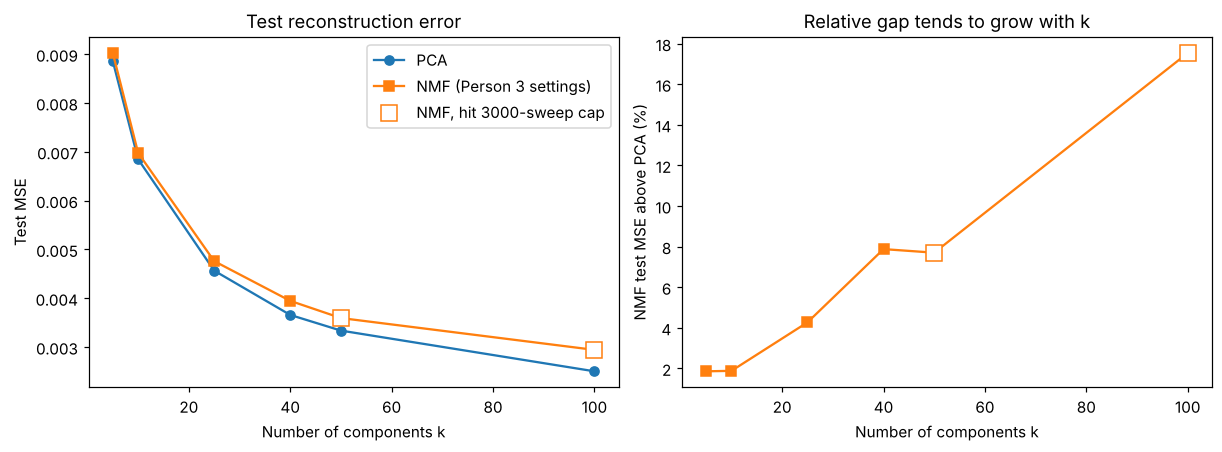

In [28]:
rows = []
for k in K_GRID:
    fit = base if k == K else fit_nmf(k)
    with threadpool_limits(limits=1):
        pca_k = PCA(n_components=k, svd_solver="full").fit(X_train)
    pca_test = mse(X_test, pca_k.inverse_transform(pca_k.transform(X_test)))
    rows.append({"k": k, "PCA test MSE": pca_test, "NMF test MSE": fit["test_mse"],
                 "NMF vs PCA (%)": 100 * (fit["test_mse"] / pca_test - 1),
                 "NMF sweeps": fit["iters"], "Hit iteration cap": fit["hit_cap"]})
    print(f"k = {k:3d} done ({time.time() - T_START:.0f} s elapsed)", flush=True)
grid = pd.DataFrame(rows)
print(grid.to_string(index=False, formatters={"PCA test MSE": "{:.6f}".format, "NMF test MSE": "{:.6f}".format,
                                               "NMF vs PCA (%)": "{:.2f}".format}))
grid.to_csv(OUT / "k_grid.csv", index=False)

# Cross-check against Person 2's reported PCA test MSE (6 decimals) -- informational.
P2_REPORTED = {5: 0.008860, 10: 0.006848, 25: 0.004565, 50: 0.003337, 100: 0.002503}
p2_check = {int(row["k"]): bool(abs(row["PCA test MSE"] - P2_REPORTED[int(row["k"])]) < 5.1e-7)
            for _, row in grid.iterrows() if int(row["k"]) in P2_REPORTED}
print("PCA test MSE matches Person 2's table:", p2_check)

fig, axes = plt.subplots(1, 2, figsize=(11, 4), layout="constrained")
capped = grid[grid["Hit iteration cap"]]
axes[0].plot(grid["k"], grid["PCA test MSE"], "o-", label="PCA")
axes[0].plot(grid["k"], grid["NMF test MSE"], "s-", label="NMF (Person 3 settings)")
axes[0].plot(capped["k"], capped["NMF test MSE"], "s", mfc="white", mec="C1", ms=10,
             label="NMF, hit 3000-sweep cap")
axes[0].set(xlabel="Number of components k", ylabel="Test MSE", title="Test reconstruction error")
axes[0].legend()
axes[1].plot(grid["k"], grid["NMF vs PCA (%)"], "s-", color="C1")
axes[1].plot(capped["k"], capped["NMF vs PCA (%)"], "s", mfc="white", mec="C1", ms=10)
axes[1].set(xlabel="Number of components k", ylabel="NMF test MSE above PCA (%)",
            title="Relative gap tends to grow with k")
fig.savefig(OUT / "07_k_grid.png", dpi=160, bbox_inches="tight")
plt.show()

NMF's test error is above PCA's at every component count tried, and the relative gap tends to grow with $k$: it is small when the representation is tiny and clearly larger at 50 and 100 components. The fits at the largest $k$ stopped at the iteration cap, so the exact percentages there are likely overstated and should be read as direction, not as measurements. We therefore describe the trend rather than quote a single gap as a property of NMF.

### 6.2 Initialization and stopping tolerance

The $k=40$ result above comes from one deterministic initialization (`nndsvda`) and one tolerance. To see how much the gap depends on those choices we refit with a stricter tolerance (`tol=1e-5`, up to 6000 sweeps) and with several random initializations (Person 3's other settings unchanged). Random starts differ only in `random_state`.

tolerance run done (350 s elapsed)


seed 0 done (387 s elapsed)


seed 1 done (423 s elapsed)


seed 2 done (457 s elapsed)


seed 3 done (492 s elapsed)


seed 4 done (527 s elapsed)


                             Variant  Sweeps  Hit iteration cap  Train MSE   Test MSE Test MSE vs PCA (%)
        nndsvda, tol 1e-4 (Person 3)    1472              False 0.00307863 0.00394635                7.88
nndsvda, tol 1e-5, up to 6000 sweeps    6000               True 0.00305941 0.00391911                7.13
                 random init, seed 0    3000               True 0.00305999 0.00385909                5.49
                 random init, seed 1    3000               True 0.00306356 0.00386743                5.72
                 random init, seed 2    3000               True 0.00305411 0.00387407                5.90
                 random init, seed 3    3000               True 0.00306074 0.00387127                5.83
                 random init, seed 4    3000               True 0.00305952 0.00389871                6.58

Random initializations: test MSE mean 0.00387411, sd 1.49e-05
Gap to PCA across all variants: 5.5% to 7.9%


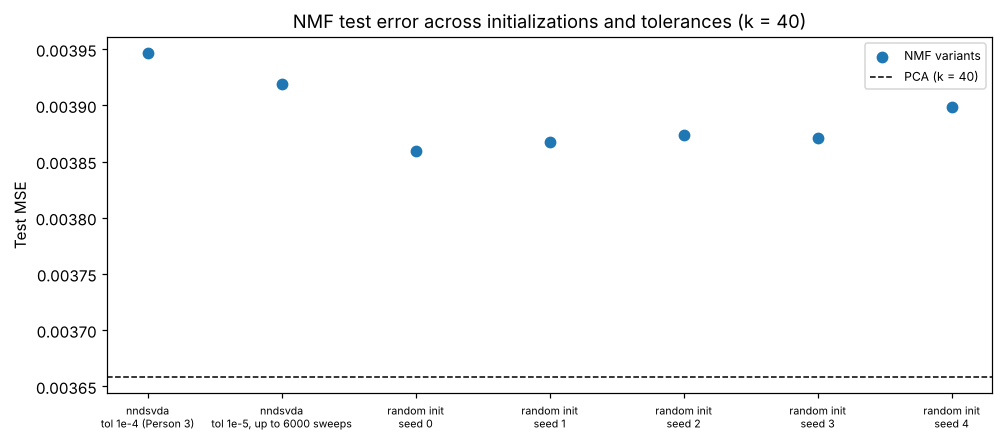

In [29]:
variants = [("nndsvda, tol 1e-4 (Person 3)", base),
            ("nndsvda, tol 1e-5, up to 6000 sweeps", fit_nmf(K, tol=1e-5, max_iter=6000))]
print(f"tolerance run done ({time.time() - T_START:.0f} s elapsed)", flush=True)
for seed in SEEDS:
    variants.append((f"random init, seed {seed}", fit_nmf(K, init="random", random_state=seed)))
    print(f"seed {seed} done ({time.time() - T_START:.0f} s elapsed)", flush=True)

init_table = pd.DataFrame([{
    "Variant": name, "Sweeps": v["iters"], "Hit iteration cap": v["hit_cap"],
    "Train MSE": v["train_mse"], "Test MSE": v["test_mse"],
    "Test MSE vs PCA (%)": 100 * (v["test_mse"] / pca_test_mse - 1)} for name, v in variants])
print(init_table.to_string(index=False, formatters={"Train MSE": "{:.8f}".format, "Test MSE": "{:.8f}".format,
                                                     "Test MSE vs PCA (%)": "{:.2f}".format}))
random_rows = init_table[init_table["Variant"].str.startswith("random")]
print(f"\nRandom initializations: test MSE mean {random_rows['Test MSE'].mean():.8f}, "
      f"sd {random_rows['Test MSE'].std(ddof=1):.2e}")
print(f"Gap to PCA across all variants: {init_table['Test MSE vs PCA (%)'].min():.1f}% to "
      f"{init_table['Test MSE vs PCA (%)'].max():.1f}%")
init_table.to_csv(OUT / "init_sensitivity_k40.csv", index=False)

fig, ax = plt.subplots(figsize=(9, 3.9), layout="constrained")
ax.scatter(range(len(init_table)), init_table["Test MSE"], s=45, zorder=3, label="NMF variants")
ax.axhline(pca_test_mse, color="k", ls="--", lw=1, label="PCA (k = 40)")
ax.set_xticks(range(len(init_table)))
ax.set_xticklabels([v.replace(", ", "\n", 1) for v in init_table["Variant"]], fontsize=7)
ax.set(ylabel="Test MSE", title="NMF test error across initializations and tolerances (k = 40)")
ax.legend(fontsize=8)
fig.savefig(OUT / "08_init_sensitivity.png", dpi=160, bbox_inches="tight")
plt.show()

The stopping rule and the initialization both matter. The stricter-tolerance run and the random starts reach lower error than Person 3's run, even though they typically stop at the iteration cap (see the \"Hit iteration cap\" column), so Person 3's solution, which satisfied the numerical tolerance without a warning, is not the best this model class can do here. The estimated gap to PCA at $k=40$ therefore moves by a couple of percentage points across these variants. PCA stays lower in every variant. We report the gap as a range, not as one fixed number, and the original single-run percentage should be read as the upper end of that range.

## 7. Limitations and what our evidence supports

1. **Local optimization and stopping.** Joint nonconvexity permits different solutions, and Vavasis (2008) shows exact NMF is NP-hard. Section 6.2 shows the consequence: different initializations and tolerances give different solutions and a gap to PCA that varies by a couple of percentage points. No convergence warning means the numerical criterion was satisfied, not that the global minimum was found.
2. **Non-unique factors.** For any positive diagonal matrix $D$, $(WD)(D^{-1}H)=WH$. Components can also be permuted. Therefore, raw coefficient sizes and component indices are not absolute importance measures. Donoho and Stodden (2003) study when a decomposition into parts is identifiable at all; our experiment does not check those conditions.
3. **Additive does not guarantee localized.** Nonnegative patterns can overlap, be dense, or represent illumination. Section 4.1 measures this: the patterns are only modestly sparser than PCA loadings and most images use most patterns. We did not test sparse or spatially constrained variants (for example Hoyer, 2004), which might behave differently.
4. **Limited test population.** Every identity appears in both splits. These results concern new photos of known individuals. Testing entirely unseen identities would require a subject-disjoint split.
5. **One split and one metric.** We now vary $k$, but with a single split and no validation set for model selection. MSE alone does not measure interpretability, recognition accuracy, or perceptual quality.
6. **Different model geometry.** PCA gives a globally optimal rank-$k$ reconstruction of the centered training matrix under squared error, and the uncentered SVD is optimal without a mean. These facts do not guarantee lower error on every unseen image. NMF imposes nonnegativity and uses iterative optimization; its fitted solution need not attain the best possible NMF error.
7. **Iteration cap at large $k$.** NMF fits at the larger component counts stop at the 3000-sweep limit, so their errors, and the gaps in Section 6.1, are upper bounds.

The following identity demonstrates the scaling ambiguity without changing the reconstruction.

In [30]:
scales = np.linspace(0.5, 2.0, K)
W_rescaled = W_test * scales[None, :]
H_rescaled = H / scales[:, None]
max_change = np.max(np.abs(W_rescaled @ H_rescaled - Xn_test))
assert np.allclose(W_rescaled @ H_rescaled, Xn_test)
print(f"Maximum reconstruction change after inverse rescaling: {max_change:.3e}")

Maximum reconstruction change after inverse rescaling: 3.331e-16


### Consistency check between the text and the computed values

The cell below fails if a statement made in the text above is no longer supported by the numbers computed in this run (for example after changing the data or the settings).

In [31]:
checks = {
    "test encoding is accurate (Section 3.1a)": -1e-12 <= mse_transform - mse_exact < 1e-7,
    "training error falls monotonically and stays above the Eckart-Young bound": bool(
        np.all(np.diff(curve) < 0) and curve[-1] >= lower_bound_train_mse),
    "error is near its final value after ~100 sweeps (Section 3.1b)":
        curve[checkpoints.index(100)] / curve[-1] < 1.10,
    "NMF patterns are sparser than |PCA| loadings but far from sparse (Section 4.1)":
        hoyer_pca.mean() < hoyer_nmf.mean() < 0.5,
    "a typical image uses roughly three quarters of the 40 patterns (Section 4.1)": 0.6 <= active_per_image.mean() / K <= 0.9,
    "no single contribution dominates (Section 4)": share[0] < 0.25,
    "PCA beats NMF on train and test at k = 40": bool(
        results.loc[0, "Train MSE"] < results.loc[3, "Train MSE"] and pca_test_mse < nmf_test_mse),
    "uncentered SVD test error within 1% of PCA (Section 5)":
        abs(results.loc[2, "Test MSE"] / pca_test_mse - 1) < 0.01,
    "PCA with 39 components + mean still beats NMF (Section 5)": results.loc[1, "Test MSE"] < nmf_test_mse,
    "NMF training error is not below the Eckart-Young bound": base["train_mse"] >= lower_bound_train_mse,
    "PCA lower on a majority of test images and CI excludes zero": n_pca_better > 40 and ci_low > 0,
    "row 166 has the largest relative gap among the five displayed images":
        int(test_idx[int(np.argmax(five_gap))]) == 166,
    "NMF above PCA at every k in the grid (Section 6.1)": bool((grid["NMF vs PCA (%)"] > 0).all()),
    "gap is larger at the largest k than at the smallest (Section 6.1)":
        grid["NMF vs PCA (%)"].iloc[-1] > grid["NMF vs PCA (%)"].iloc[0],
    "stricter tolerance and random starts reach lower test error than Person 3's run (Section 6.2)": bool(
        init_table.loc[1, "Test MSE"] < base["test_mse"] and random_rows["Test MSE"].mean() < base["test_mse"]),
    "Person 3's single run gives the largest gap among the variants (Section 6.2)":
        abs(init_table.loc[0, "Test MSE vs PCA (%)"] - init_table["Test MSE vs PCA (%)"].max()) < 1e-9,
    "PCA stays lower in every initialization variant (Section 6.2)": bool((init_table["Test MSE vs PCA (%)"] > 0).all()),
    "gap varies by a couple of percentage points across variants (Section 6.2)":
        0.5 < init_table["Test MSE vs PCA (%)"].max() - init_table["Test MSE vs PCA (%)"].min() < 4.0,
}
for name, ok in checks.items():
    print(("OK    " if ok else "FAILED"), name)
assert all(checks.values()), "A statement in the text is not supported by this run; revisit the text."

OK     test encoding is accurate (Section 3.1a)
OK     training error falls monotonically and stays above the Eckart-Young bound
OK     error is near its final value after ~100 sweeps (Section 3.1b)
OK     NMF patterns are sparser than |PCA| loadings but far from sparse (Section 4.1)
OK     a typical image uses roughly three quarters of the 40 patterns (Section 4.1)
OK     no single contribution dominates (Section 4)
OK     PCA beats NMF on train and test at k = 40
OK     uncentered SVD test error within 1% of PCA (Section 5)
OK     PCA with 39 components + mean still beats NMF (Section 5)
OK     NMF training error is not below the Eckart-Young bound
OK     PCA lower on a majority of test images and CI excludes zero
OK     row 166 has the largest relative gap among the five displayed images
OK     NMF above PCA at every k in the grid (Section 6.1)
OK     gap is larger at the largest k than at the smallest (Section 6.1)
OK     stricter tolerance and random starts reach lower test error 

## 8. Conclusion

NMF learns a nonnegative dictionary of patterns and represents each face as their nonnegative weighted sum. Coordinate descent fits the training factors; test encoding adjusts only the coefficients, and we verified that this encoding is solved essentially exactly. The representation gives a direct additive explanation of every reconstruction, at the price of a nonconvex training problem and factors that are not unique.

At 40 components on this fixed split, PCA achieves lower pixel reconstruction error than NMF in every variant we tried, on most individual test images, and at every component count on Person 2's grid, with the relative gap tending to grow as $k$ increases. The gap is not explained by PCA's mean term. It reflects the nonnegativity constraint together with imperfect optimization, and its size at $k=40$ depends on the initialization and tolerance (roughly 5.5–8% in our runs), so it should be reported as a range.

The learned NMF patterns are broad and overlapping: only modestly sparser than PCA loadings, with most images using most patterns. This experiment therefore demonstrates additive interpretability more clearly than a clean parts-based decomposition.

Our strongest interpretability claim is that NMF contributions can be inspected as positive additions. We do not claim that nonnegativity alone produces independent facial parts, that one method is universally better, or that these results extend to unseen identities.

In [32]:
# Record the exact inputs and settings used for this notebook's results.
warning_log = [{"stage": stage, "category": item.category.__name__, "message": str(item.message)}
               for stage, items in [("training", fit_warnings), ("test encoding", test_warnings)]
               for item in items]
metadata = {
    "data_sha256": hashlib.sha256(DATA_PATH.read_bytes()).hexdigest(),
    "quick_mode": QUICK, "component_count": K, "k_grid": K_GRID, "random_seeds": SEEDS,
    "nmf_parameters": nmf.get_params(), "nmf_training_iterations": int(nmf.n_iter_),
    "warnings": warning_log,
    "python_version": platform.python_version(), "numpy_version": np.__version__,
    "scipy_version": scipy.__version__, "sklearn_version": sklearn.__version__,
    "results_k40": results.to_dict(orient="records"),
    "k_grid_results": grid.to_dict(orient="records"),
    "init_sensitivity": init_table.to_dict(orient="records"),
    "paired_comparison": {"mean_difference": float(diff.mean()), "ci95": [float(ci_low), float(ci_high)],
                          "pca_better_on": n_pca_better, "n_images": int(len(diff))},
    "matches_person3_reported": p3_check, "matches_person2_reported_pca": p2_check,
    "text_checks_passed": bool(all(checks.values())),
    "test_example_positions": list(range(5)),
    "error_definition": "Mean squared pixel error, without reconstruction clipping",
    "runtime_seconds": round(time.time() - T_START, 1),
}
(OUT / "run_metadata.json").write_text(json.dumps(metadata, indent=2, default=str), encoding="utf-8")
print(f"Saved figures, result tables, and run_metadata.json in {OUT}/ "
      f"(total run time {time.time() - T_START:.0f} s).")

Saved figures, result tables, and run_metadata.json in p4_results/ (total run time 528 s).


## References and connection to the team's work

- Lee, D. D., & Seung, H. S. (1999). Learning the parts of objects by non-negative matrix factorization. *Nature*, 401(6755), 788–791.
- Lee, D. D., & Seung, H. S. (2001). Algorithms for non-negative matrix factorization. *Advances in Neural Information Processing Systems 13* (NIPS 2000).
- Cichocki, A., & Phan, A.-H. (2009). Fast local algorithms for large scale nonnegative matrix and tensor factorizations. *IEICE Transactions on Fundamentals of Electronics, Communications and Computer Sciences*, E92-A(3), 708–721.
- Donoho, D., & Stodden, V. (2003). When does non-negative matrix factorization give a correct decomposition into parts? *Advances in Neural Information Processing Systems 16* (NIPS 2003).
- Vavasis, S. A. (2008). On the complexity of nonnegative matrix factorization. arXiv:0708.4149.
- Hoyer, P. O. (2004). Non-negative matrix factorization with sparseness constraints. *Journal of Machine Learning Research*, 5, 1457–1469.
- [scikit-learn: NMF API](https://scikit-learn.org/stable/modules/generated/sklearn.decomposition.NMF.html): objective, initialization, solvers, and test transformation.
- [scikit-learn: Matrix decomposition guide](https://scikit-learn.org/stable/modules/decomposition.html#nmf): nonnegative representations and comparison with PCA.
- Team inputs: `olivetti_preprocessed.npz`; Part P3 of this notebook (NMF configuration and reported MSE values); Part P2 (PCA baseline, component grid, five fixed test images).

The mathematical coordinate-update derivation follows directly from the squared-error objective above. Experimental values and figures are generated by this notebook from the supplied team data. Face images: AT&T Laboratories Cambridge / Olivetti Faces.

---
<a id="showcase"></a>
# ▌RESULTS SHOWCASE — talk-ready summary

> New in this combined notebook. It reads the files written by Parts P2, P3 and P4 (so every number below comes from this run), checks that the parts agree with each other, and produces two slide-ready figures in `showcase/`. Run the parts above first.

## Suggested 12-minute talk (+ 3 minutes of questions)

| Slide | Time | Message | Show |
|---|---|---|---|
| 1 | 1 min | The question: can a face be built by *adding* patterns, and what does that cost compared with PCA? | `showcase/gallery_pca_vs_nmf.png` |
| 2 | 1.5 min | The NMF model, $X\approx WH$ with $W,H\ge 0$, and its squared-error objective | Part P4, Section 2 |
| 3 | 2 min | How it is learned: alternating updates on a non-convex problem; the training error falls fast and then slowly | `p4_results/04_convergence.png` |
| 4 | 2.5 min | What it learns: broad, overlapping patterns, not isolated facial parts; one face as a sum of contributions | `p4_results/01_components.png`, `02_additive_reconstruction.png`, `05_sparsity.png` |
| 5 | 2 min | How well it reconstructs, compared with PCA and with the best possible unconstrained rank-40 model | comparison table (below), `06_paired_errors.png` |
| 6 | 1.5 min | Robustness: other component counts, other initializations | `showcase/headline_results.png` |
| 7 | 1.5 min | Limitations and take-aways | slide text (below) |

Every member must be able to explain every slide, and members who do not present must answer at least one question in the Q&A.

In [33]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from IPython.display import Markdown, display

SHOW = Path("showcase")
SHOW.mkdir(exist_ok=True)
P4_DIR = Path("p4_results")

# Files written by the earlier parts of this notebook (ROOT is defined in Part P3).
p2_table = pd.read_csv(Path("pca_results") / "03_pca_results.csv")
p3_metrics = pd.read_csv(ROOT / "outputs" / "team_nmf" / "metrics.csv").iloc[0]
cmp40 = pd.read_csv(P4_DIR / "comparison_k40.csv").set_index("Method")
grid_df = pd.read_csv(P4_DIR / "k_grid.csv")
init_df = pd.read_csv(P4_DIR / "init_sensitivity_k40.csv")
sparse = pd.read_csv(P4_DIR / "sparsity_k40.csv").set_index("Quantity")
meta4 = json.loads((P4_DIR / "run_metadata.json").read_text(encoding="utf-8"))

# The parts must agree with each other on every shared number.
pca40, nmf40 = float(cmp40.loc["PCA", "Test MSE"]), float(cmp40.loc["NMF", "Test MSE"])
svd40 = float(cmp40.loc["Uncentered SVD", "Test MSE"])
assert np.isclose(nmf40, p3_metrics["test_mse"], rtol=1e-8), "P4 and P3 disagree on the NMF test MSE"
assert np.isclose(float(cmp40.loc["NMF", "Train MSE"]), p3_metrics["train_mse"], rtol=1e-8), "P4 and P3 disagree on the NMF train MSE"
for _, row in p2_table.iterrows():
    match = grid_df.loc[grid_df["k"] == int(row["Components"]), "PCA test MSE"]
    if len(match):
        assert np.isclose(float(match.iloc[0]), row["Test MSE"], rtol=1e-8), f"P2 and P4 disagree on PCA at k={int(row['Components'])}"
print("Cross-part check passed: P3 and P4 agree on NMF at k = 40; P2 and P4 agree on PCA at every shared k.")

gap40 = 100 * (nmf40 / pca40 - 1)
gaps = init_df["Test MSE vs PCA (%)"]
assert (gaps > 0).all() and (grid_df["NMF vs PCA (%)"] > 0).all()
first, last = grid_df.iloc[0], grid_df.iloc[-1]
pair = meta4["paired_comparison"]
display(Markdown(f'''
### Headline numbers (computed from this run)

- **Reconstruction at 40 components.** Test MSE is **{pca40:.6f}** for PCA and **{nmf40:.6f}** for NMF, so NMF is **{gap40:+.1f}%** above PCA. An uncentered SVD (no mean term, signed factors) reaches {svd40:.6f}, so the gap is not caused by PCA's mean term.
- **It depends on the optimizer.** Across the initializations and tolerances tried, the gap to PCA ranges from **{gaps.min():.1f}% to {gaps.max():.1f}%**; PCA is lower in every variant.
- **It depends on k.** NMF is above PCA at every component count tried: **{first['NMF vs PCA (%)']:.1f}%** at k = {int(first['k'])} and **{last['NMF vs PCA (%)']:.1f}%** at k = {int(last['k'])} (the fits at the largest k reached the iteration limit, so those gaps are upper bounds).
- **It is not a few unusual images.** PCA has the lower error on **{pair['pca_better_on']} of {pair['n_images']}** test images (95% bootstrap interval for the mean difference: {pair['ci95'][0]:.6f} to {pair['ci95'][1]:.6f}).
- **Interpretability.** The NMF patterns are only modestly sparse (mean Hoyer sparsity {sparse.loc['Mean Hoyer sparsity of the 40 patterns', 'NMF']}, where 0 is dense and 1 is a single pixel); a typical training image uses {sparse.loc['Mean nonzero coefficients per training image', 'NMF']} patterns.
'''))

Cross-part check passed: P3 and P4 agree on NMF at k = 40; P2 and P4 agree on PCA at every shared k.



### Headline numbers (computed from this run)

- **Reconstruction at 40 components.** Test MSE is **0.003658** for PCA and **0.003946** for NMF, so NMF is **+7.9%** above PCA. An uncentered SVD (no mean term, signed factors) reaches 0.003658, so the gap is not caused by PCA's mean term.
- **It depends on the optimizer.** Across the initializations and tolerances tried, the gap to PCA ranges from **5.5% to 7.9%**; PCA is lower in every variant.
- **It depends on k.** NMF is above PCA at every component count tried: **1.9%** at k = 5 and **17.5%** at k = 100 (the fits at the largest k reached the iteration limit, so those gaps are upper bounds).
- **It is not a few unusual images.** PCA has the lower error on **74 of 80** test images (95% bootstrap interval for the mean difference: 0.000233 to 0.000344).
- **Interpretability.** The NMF patterns are only modestly sparse (mean Hoyer sparsity 0.317, where 0 is dense and 1 is a single pixel); a typical training image uses 29.8 of 40 patterns.


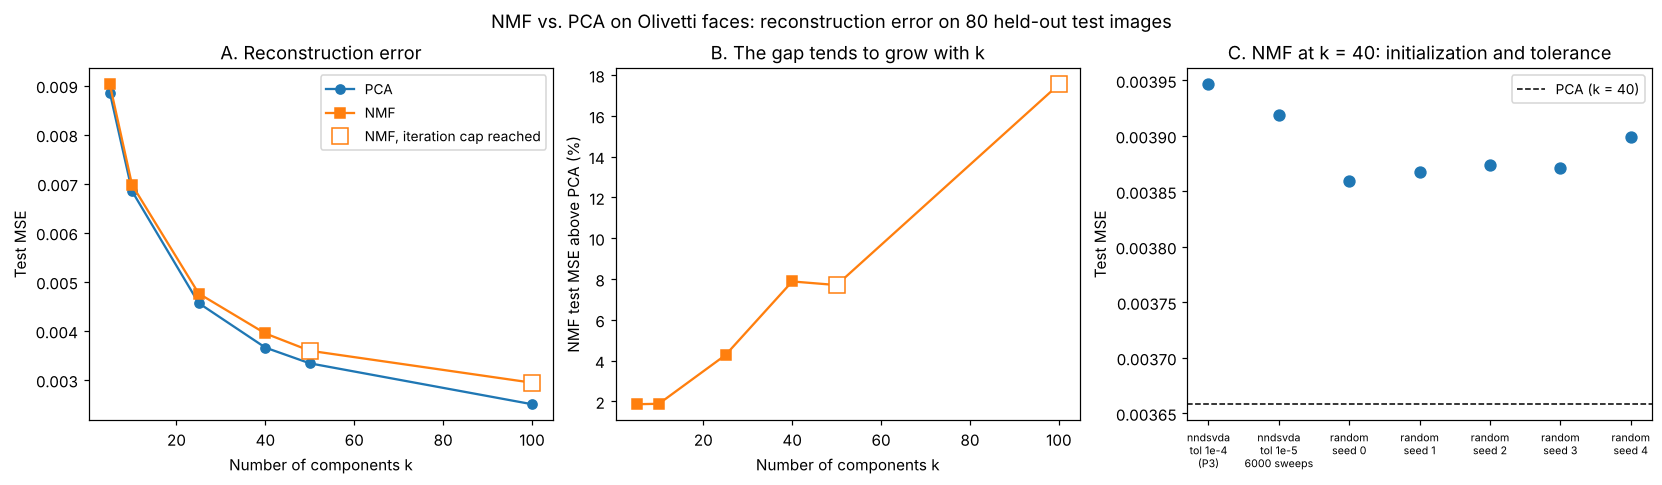

In [34]:
# Slide-ready headline figure: error versus k, the gap versus k, and the k = 40 initialization study.
capped = grid_df[grid_df["Hit iteration cap"]]
fig, axes = plt.subplots(1, 3, figsize=(15, 4.3), layout="constrained")
ax = axes[0]
ax.plot(grid_df["k"], grid_df["PCA test MSE"], "o-", label="PCA")
ax.plot(grid_df["k"], grid_df["NMF test MSE"], "s-", label="NMF")
ax.plot(capped["k"], capped["NMF test MSE"], "s", mfc="white", mec="C1", ms=10, label="NMF, iteration cap reached")
ax.set(xlabel="Number of components k", ylabel="Test MSE", title="A. Reconstruction error")
ax.legend(fontsize=9)
ax = axes[1]
ax.plot(grid_df["k"], grid_df["NMF vs PCA (%)"], "s-", color="C1")
ax.plot(capped["k"], capped["NMF vs PCA (%)"], "s", mfc="white", mec="C1", ms=10)
ax.set(xlabel="Number of components k", ylabel="NMF test MSE above PCA (%)", title="B. The gap tends to grow with k")
ax = axes[2]
ax.scatter(range(len(init_df)), init_df["Test MSE"], s=50, zorder=3)
ax.axhline(pca40, color="k", ls="--", lw=1, label="PCA (k = 40)")
ax.set_xticks(range(len(init_df)))
def short_label(v):
    if "(Person 3)" in v:
        return "nndsvda\ntol 1e-4\n(P3)"
    if v.startswith("nndsvda"):
        return "nndsvda\ntol 1e-5\n6000 sweeps"
    return "random\n" + v.split(", ")[-1]
ax.set_xticklabels([short_label(v) for v in init_df["Variant"]], fontsize=7)
ax.set(ylabel="Test MSE", title="C. NMF at k = 40: initialization and tolerance")
ax.legend(fontsize=9)
fig.suptitle("NMF vs. PCA on Olivetti faces: reconstruction error on 80 held-out test images", fontsize=12)
fig.savefig(SHOW / "headline_results.png", dpi=200, bbox_inches="tight")
plt.show()

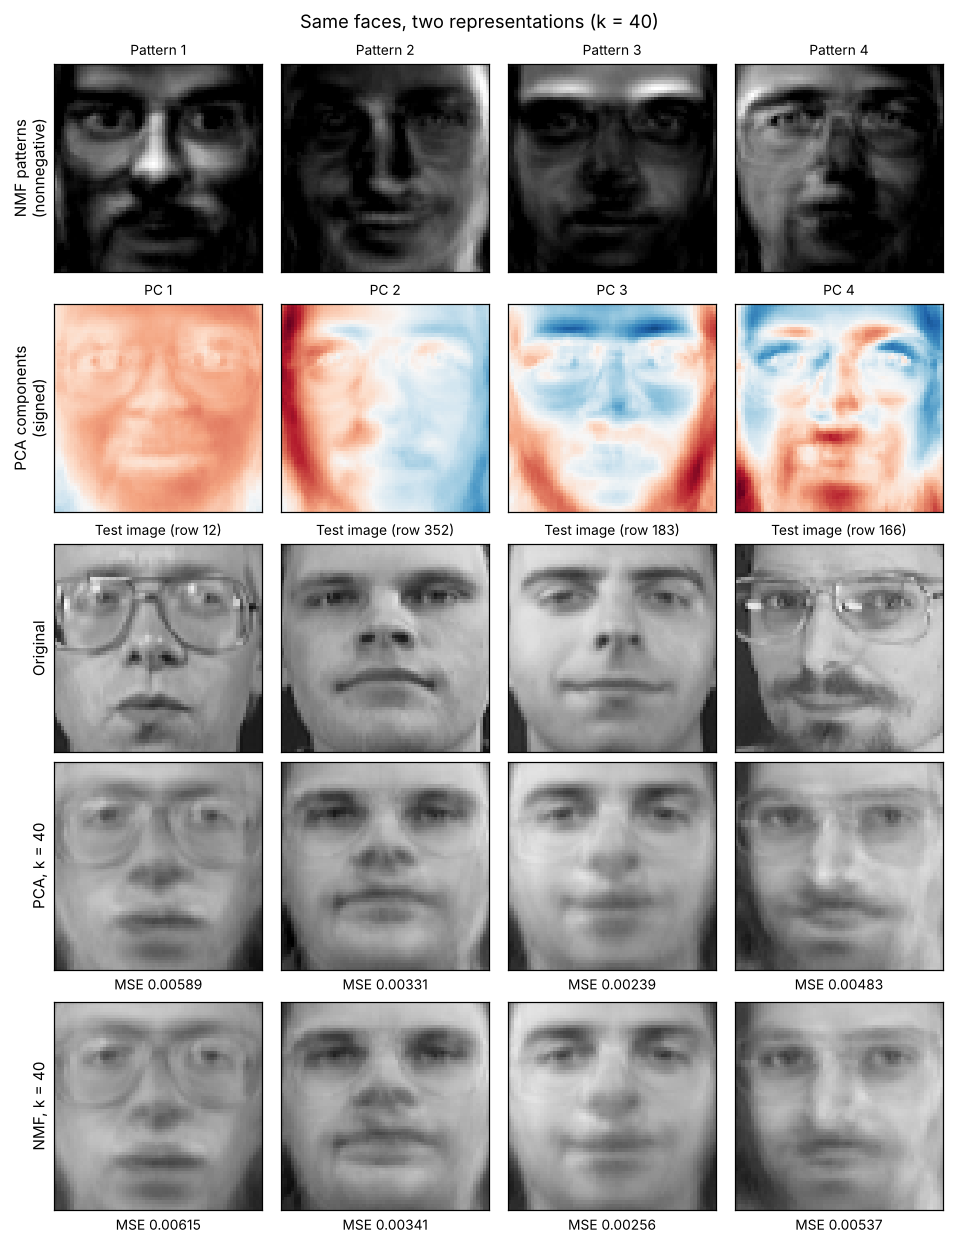

In [35]:
# Slide-ready gallery: what each method learns and what it reconstructs (k = 40; uses variables from Part P4).
n = 4
fig, axes = plt.subplots(5, n, figsize=(8.6, 11.2), layout="constrained")
limit = np.abs(pca.components_[:n]).max()
for j in range(n):
    axes[0, j].imshow((H[j] / max(H[j].max(), 1e-12)).reshape(64, 64), cmap="gray", vmin=0, vmax=1)
    axes[0, j].set_title(f"Pattern {j + 1}", fontsize=9)
    axes[1, j].imshow(pca.components_[j].reshape(64, 64), cmap="RdBu_r", vmin=-limit, vmax=limit)
    axes[1, j].set_title(f"PC {j + 1}", fontsize=9)
    for row, values in zip((2, 3, 4), (X_test, Xp_test, Xn_test)):
        axes[row, j].imshow(np.clip(values[j], 0, 1).reshape(64, 64), cmap="gray", vmin=0, vmax=1)
    axes[2, j].set_title(f"Test image (row {test_idx[j]})", fontsize=9)
    axes[3, j].set_xlabel(f"MSE {err_pca[j]:.5f}", fontsize=9)
    axes[4, j].set_xlabel(f"MSE {err_nmf[j]:.5f}", fontsize=9)
for ax, label in zip(axes[:, 0], ["NMF patterns\n(nonnegative)", "PCA components\n(signed)", "Original", "PCA, k = 40", "NMF, k = 40"]):
    ax.set_ylabel(label, fontsize=10)
for ax in axes.flat:
    ax.set_xticks([]); ax.set_yticks([])
fig.suptitle("Same faces, two representations (k = 40)", fontsize=12)
fig.savefig(SHOW / "gallery_pca_vs_nmf.png", dpi=200, bbox_inches="tight")
plt.show()

## Take-aways for the last slide

1. **NMF explains a face as a sum of nonnegative patterns**, so every reconstruction can be read as positive additions. On these images the learned patterns are broad and overlapping, not isolated eyes, noses or mouths.
2. **At the same number of components PCA reconstructs the held-out faces better**, and the gap tends to grow with the number of components. It is not caused by PCA's mean term; it is the price of the nonnegativity constraint together with imperfect optimization.
3. **The size of NMF's gap depends on how it is optimized.** Different initializations and tolerances change it by a couple of percentage points, so we report a range, not one number.
4. **Limits of the evidence:** one split in which every person appears in both training and test images, one error measure (per-pixel MSE), and no claim about recognition accuracy or about unseen people.

## Likely questions and short answers

| Question | Short answer | Where the evidence is |
|---|---|---|
| Why is NMF's error higher than PCA's? | PCA gives the best possible rank-k fit without constraints; NMF must keep every entry nonnegative and solves a non-convex problem, so it cannot do better and usually does worse. | P4 Sections 3.1 and 5 (Eckart–Young line, uncentered SVD) |
| Is the gap real, or just an optimizer artifact? | It depends on the optimizer by a couple of percentage points, but PCA is lower in every variant we tried and on most individual test images. | P4 Sections 5 and 6.2 |
| Then why use NMF at all? | For interpretability: every reconstruction is an addition of nonnegative contributions. Here that is a modest advantage, because the patterns are broad. | P4 Section 4 and 4.1 |
| Did NMF find "parts of faces"? | Not in this experiment: the patterns are dense and overlapping. We did not test sparsity-promoting variants. | P4 Section 4.1 and Limitation 3 |
| Are the factors unique? | No: each pattern can be rescaled against its coefficient, and patterns can be reordered; exact NMF is NP-hard. | P4 Limitations 1 and 2, scaling demo |
| How were test images encoded? | With the patterns fixed, each test image gets the best nonnegative coefficients; we checked this against an exact solver. | P4 Section 3.1(a) |
| Why unclipped MSE? | All team parts use the same definition; clipping is only for display. | P2 and P3 notes |
| Does this say anything about face recognition? | No. Identity labels were not used, and we measured reconstruction error only. | P4 Limitations 4 and 5 |
| Are the test faces really unseen? | The photos are, but every person also appears in the training set. | P2 final note, P4 Limitation 4 |